# 02 – Analysis: set vs graph neural networks for xG

**Question:** does modelling the players around a shot as a **graph** (players connected to each other) predict goals
better than treating them as an unordered **set** (each player seen on its own)?

**Input:** `data/processed/` from `01-Data.ipynb`. **Output:** tables in `results/`, figures in `figures/`.

**Reading order**
1. Load and prepare the data
2. How a shot becomes a graph
3. The two models (one shared code path: the set model is the graph model with no message passing)
4. Training and evaluation setup
5. Experiments: tuning choices on the validation set (edge rule → region size → aggregation → features → training data)
6. Final test: set vs graph on held-out matches
7. Scaling: what happens with far more data
8. Conclusions

**Run time:** about an hour on a laptop CPU in `full` mode. `smoke` mode checks that everything runs in a few minutes.

In [1]:
import json, time, copy, os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Polygon
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, roc_curve

warnings.filterwarnings("ignore", category=UserWarning)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_THREADS = torch.get_num_threads()
print("torch", torch.__version__, "| device:", DEVICE, "| CPU threads:", N_THREADS)

torch 2.15.0+cpu | device: cpu | CPU threads: 2


## 0. Settings
* `MODE = "smoke"`: tiny run to check the code (minutes). `MODE = "full"`: the real results.
* Tuning experiments use one seed (they are for choosing settings). The final test uses three seeds.

In [2]:
MODE = "full"   # "smoke" | "full"

SETTINGS = {
    "smoke": dict(tune_seeds=[0], final_seeds=[0, 1], curve_seeds=[0], max_epochs=2, max_train=3000,
                  synth=[1, 2], threads_batches=5),
    "full":  dict(tune_seeds=[0], final_seeds=[0, 1, 2], curve_seeds=[0, 1, 2], max_epochs=25, max_train=None,
                  synth=[1, 2, 5, 10], threads_batches=40),
}
S_ = SETTINGS[MODE]
TUNE_SEEDS, FINAL_SEEDS, CURVE_SEEDS = S_["tune_seeds"], S_["final_seeds"], S_["curve_seeds"]
MAX_EPOCHS, MAX_TRAIN = S_["max_epochs"], S_["max_train"]
PATIENCE = 4               # stop when validation log loss has not improved for 4 epochs

PROC, RESULTS_DIR, FIGURES = Path("data/processed"), Path("results"), Path("figures")
RESULTS_DIR.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

GOAL_X, POST_L, POST_R = 120.0, 36.0, 44.0     # StatsBomb pitch: everyone attacks towards x = 120

## 1. Load and prepare the data

**Evaluation sets.** All selection and the headline result use matches from the four **complete 2015/16 seasons**
(`val15`, `test15`), because single-club seasons are a biased sample (one strong team in every match).
Training uses all seasons unless Experiment 5.5 says otherwise. Single-club validation/test matches are kept for comparison.

**Scaling.** Continuous features are standardised with means and standard deviations from the **training split only**.

In [3]:
shot_df = pd.read_csv(PROC / "shot_table.csv")
player_df = pd.read_csv(PROC / "player_table.csv")
FC = json.loads((PROC / "feature_columns.json").read_text())
SHOT_FEATURES, PLAYER_BASIC, PLAYER_ENG = FC["shot_features"], FC["player_basic"], FC["player_engineered"]
print(f"shots: {shot_df.shape} | players: {player_df.shape}")

# align player rows with shot order (player_table is sorted by shot, shooter first)
shot_pos = pd.Series(np.arange(len(shot_df)), index=shot_df["shot_id"].values)
player_df["_s"] = player_df["shot_id"].map(shot_pos)
player_df = player_df.sort_values(["_s", "player_idx"], kind="stable").reset_index(drop=True)
S = len(shot_df)
NCOUNT = np.bincount(player_df["_s"].values, minlength=S)
NODE_PTR = np.concatenate([[0], np.cumsum(NCOUNT)])
assert (player_df.groupby("_s")["is_shooter"].sum() == 1).all()

# standardise continuous features (training statistics only); binary flags are left as 0/1
is_train_shot = (shot_df["split"] == "train").values
is_train_node = is_train_shot[player_df["_s"].values]
def standardise(df, cols, train_mask):
    out = df[cols].astype("float32").copy()
    for c in cols:
        if set(np.unique(out[c])) <= {0.0, 1.0}:
            continue
        mu, sd = out.loc[train_mask, c].mean(), out.loc[train_mask, c].std()
        out[c] = (out[c] - mu) / max(sd, 1e-6)
    return out.values

X_FEATS = {"basic": torch.tensor(standardise(player_df, PLAYER_BASIC, is_train_node)),
           "engineered": torch.tensor(standardise(player_df, PLAYER_BASIC + PLAYER_ENG, is_train_node))}
U = torch.tensor(standardise(shot_df, SHOT_FEATURES, is_train_shot))
Y = torch.tensor(shot_df["is_goal"].values.astype("float32"))
POS = player_df[["x", "y"]].values.astype("float32")
TEAM, KEEPER, SHOOTER = (player_df[c].values.astype(int) for c in ["teammate", "is_keeper", "is_shooter"])
MATCH_IDS, BENCH = shot_df["match_id"].values, shot_df["statsbomb_xg"].values

split, sub = shot_df["split"].values, shot_df["subset_1516"].values == 1
IDX = {"train_all": np.flatnonzero(split == "train"), "train_1516": np.flatnonzero((split == "train") & sub),
       "val": np.flatnonzero(split == "val"), "test": np.flatnonzero(split == "test")}
if MAX_TRAIN:   # smoke mode only
    rng0 = np.random.default_rng(0)
    for k in ["train_all", "train_1516"]:
        IDX[k] = np.sort(rng0.choice(IDX[k], min(MAX_TRAIN, len(IDX[k])), replace=False))
# masks inside the val / test index arrays
IN15 = {s: sub[IDX[s]] for s in ["val", "test"]}

overview = pd.DataFrame({
    name: {"shots": len(i), "matches": len(np.unique(MATCH_IDS[i])), "goal rate": Y[i].mean().item()}
    for name, i in [("train (all seasons)", IDX["train_all"]), ("train (2015/16 only)", IDX["train_1516"]),
                    ("val15", IDX["val"][IN15["val"]]), ("val single-club", IDX["val"][~IN15["val"]]),
                    ("test15", IDX["test"][IN15["test"]]), ("test single-club", IDX["test"][~IN15["test"]])]}).T
print(overview.round(3))
print(f"\nnodes per shot (incl. shooter): mean {NCOUNT.mean():.1f}, max {NCOUNT.max()}")

shots: (53556, 43) | players: (738529, 21)


                        shots  matches  goal rate
train (all seasons)   37464.0   1518.0      0.103
train (2015/16 only)  26239.0   1062.0      0.095
val15                  5521.0    223.0      0.101
val single-club        2488.0    102.0      0.128
test15                 5728.0    232.0      0.091
test single-club       2355.0     94.0      0.121

nodes per shot (incl. shooter): mean 13.8, max 22


Single-club seasons have a noticeably higher goal rate than the complete seasons. This is the first hint that they
are not a representative sample, and the reason the headline numbers use 2015/16 matches.

## 2. How a shot becomes a graph

**Nodes:** the shooter and every visible player. Each node carries the player features from `01-Data`.

**Edges** say which players exchange information. We compare four rules (Fig 3):

| rule | edges | idea |
|---|---|---|
| `none` | no edges | **set model**: each player is processed on its own, then pooled |
| `star` | shooter ↔ players in the region (+ opposition keeper) | only the players near the shot talk to the shooter |
| `star_keeper` | `star` + keeper ↔ region players | also lets the keeper "see" the players in front of them |
| `region` | every pair within {shooter, region players, keeper} | the local defensive structure is fully connected |
| `full` | every pair of players | no football knowledge in the edges; the model decides what matters |

**Region** around the shooter: a half-disc of radius `r_front` in front (towards goal), a half-disc of radius
`r_back` behind, plus the **shooting cone** (triangle shooter → posts). Default 7 yd / 4 yd. Players outside the
region are still nodes (so still in the pooled summary), they just do not send or receive messages.

**Edge features** for each edge: distance, `dx`, `dy` (all / 20 yd) and a same-team flag. This relational information
is the one thing the set model cannot see.

In [4]:
def _cross(ax, ay, bx, by, px, py):
    return (bx - ax) * (py - ay) - (by - ay) * (px - ax)

def in_cone(px, py, sx, sy):
    d1, d2, d3 = (_cross(sx, sy, GOAL_X, POST_L, px, py), _cross(GOAL_X, POST_L, GOAL_X, POST_R, px, py),
                  _cross(GOAL_X, POST_R, sx, sy, px, py))
    return ~(((d1 < 0) | (d2 < 0) | (d3 < 0)) & ((d1 > 0) | (d2 > 0) | (d3 > 0)))

def region_mask(px, py, sx, sy, r_front, r_back):
    dx, d = px - sx, np.hypot(px - sx, py - sy)
    return np.where(dx > 0, d <= r_front, d <= r_back) | in_cone(px, py, sx, sy)

def _pairs(nodes):
    a, b = np.meshgrid(nodes, nodes, indexing="ij")
    m = a != b
    return a[m], b[m]

RULES = ["none", "star", "star_keeper", "region", "full"]
REGION_RULES = ["star", "star_keeper", "region"]

def build_edges(rule, px, py, team, keeper, shooter, r_front, r_back):
    # Directed edges (src, dst) as local node indices for ONE shot.
    n = len(px)
    if rule == "none":
        return np.zeros(0, int), np.zeros(0, int)
    if rule == "full":
        return _pairs(np.arange(n))
    s = int(np.flatnonzero(shooter)[0])
    keepers = np.flatnonzero((keeper == 1) & (team == 0))
    reg = region_mask(px, py, px[s], py[s], r_front, r_back); reg[s] = False
    members = np.setdiff1d(np.union1d(np.flatnonzero(reg), keepers), [s])
    if rule == "region":
        return _pairs(np.concatenate([[s], members]))
    src, dst = [np.full(len(members), s), members], [members, np.full(len(members), s)]
    if rule == "star_keeper":
        for k in keepers:
            others = members[members != k]
            src += [np.full(len(others), k), others]; dst += [others, np.full(len(others), k)]
    return np.concatenate(src), np.concatenate(dst)

In [5]:
def _ranges(starts, counts):
    # concatenate arange(start, start + count) for many pairs, vectorised
    offs = np.repeat(np.cumsum(counts) - counts, counts)
    return np.repeat(starts, counts) + (np.arange(int(counts.sum())) - offs)

class Batch:
    def to(self, device):
        for k, v in self.__dict__.items():
            if torch.is_tensor(v):
                setattr(self, k, v.to(device))
        return self

class GraphStore:
    # Edges for every shot under one rule, stored flat. batch() glues shots into one disconnected graph.
    def __init__(self, src, dst, ecount):
        self.src, self.dst, self.ecount = src, dst, ecount
        self.eptr = np.concatenate([[0], np.cumsum(ecount)])
        self.mean_edges = float(ecount.mean())

    def batch(self, idx, feats):
        idx = np.asarray(idx)
        nc, ec = NCOUNT[idx], self.ecount[idx]
        nrows = _ranges(NODE_PTR[idx], nc)
        erows = _ranges(self.eptr[idx], ec)
        noff = np.repeat(np.cumsum(nc) - nc, ec)
        b = Batch()
        b.x = X_FEATS[feats][nrows]
        b.is_shooter = torch.from_numpy(SHOOTER[nrows] == 1)
        b.node_graph = torch.from_numpy(np.repeat(np.arange(len(idx)), nc))
        b.src = torch.from_numpy(self.src[erows].astype(np.int64) + noff)
        b.dst = torch.from_numpy(self.dst[erows].astype(np.int64) + noff)
        pos, team = torch.from_numpy(POS[nrows]), torch.from_numpy(TEAM[nrows])
        d = pos[b.src] - pos[b.dst]
        b.edge_attr = torch.cat([d.norm(dim=1, keepdim=True) / 20, d / 20,
                                 (team[b.src] == team[b.dst]).float().unsqueeze(1)], 1)
        b.n_graphs, b.u, b.y = len(idx), U[idx], Y[idx]
        return b

STORES = {}
def get_store(rule, r_front=7.0, r_back=4.0):
    key = (rule, r_front, r_back) if rule in REGION_RULES else (rule,)
    if key not in STORES:
        t0 = time.time()
        srcs, dsts, ecount = [], [], np.zeros(S, int)
        for i in range(S):
            a, b = NODE_PTR[i], NODE_PTR[i + 1]
            es, ed = build_edges(rule, POS[a:b, 0], POS[a:b, 1], TEAM[a:b], KEEPER[a:b], SHOOTER[a:b], r_front, r_back)
            srcs.append(es.astype(np.int16)); dsts.append(ed.astype(np.int16)); ecount[i] = len(es)
        STORES[key] = GraphStore(np.concatenate(srcs), np.concatenate(dsts), ecount)
        print(f"  built {key}: {STORES[key].mean_edges:.1f} directed edges per shot ({time.time() - t0:.0f}s)")
    return STORES[key]

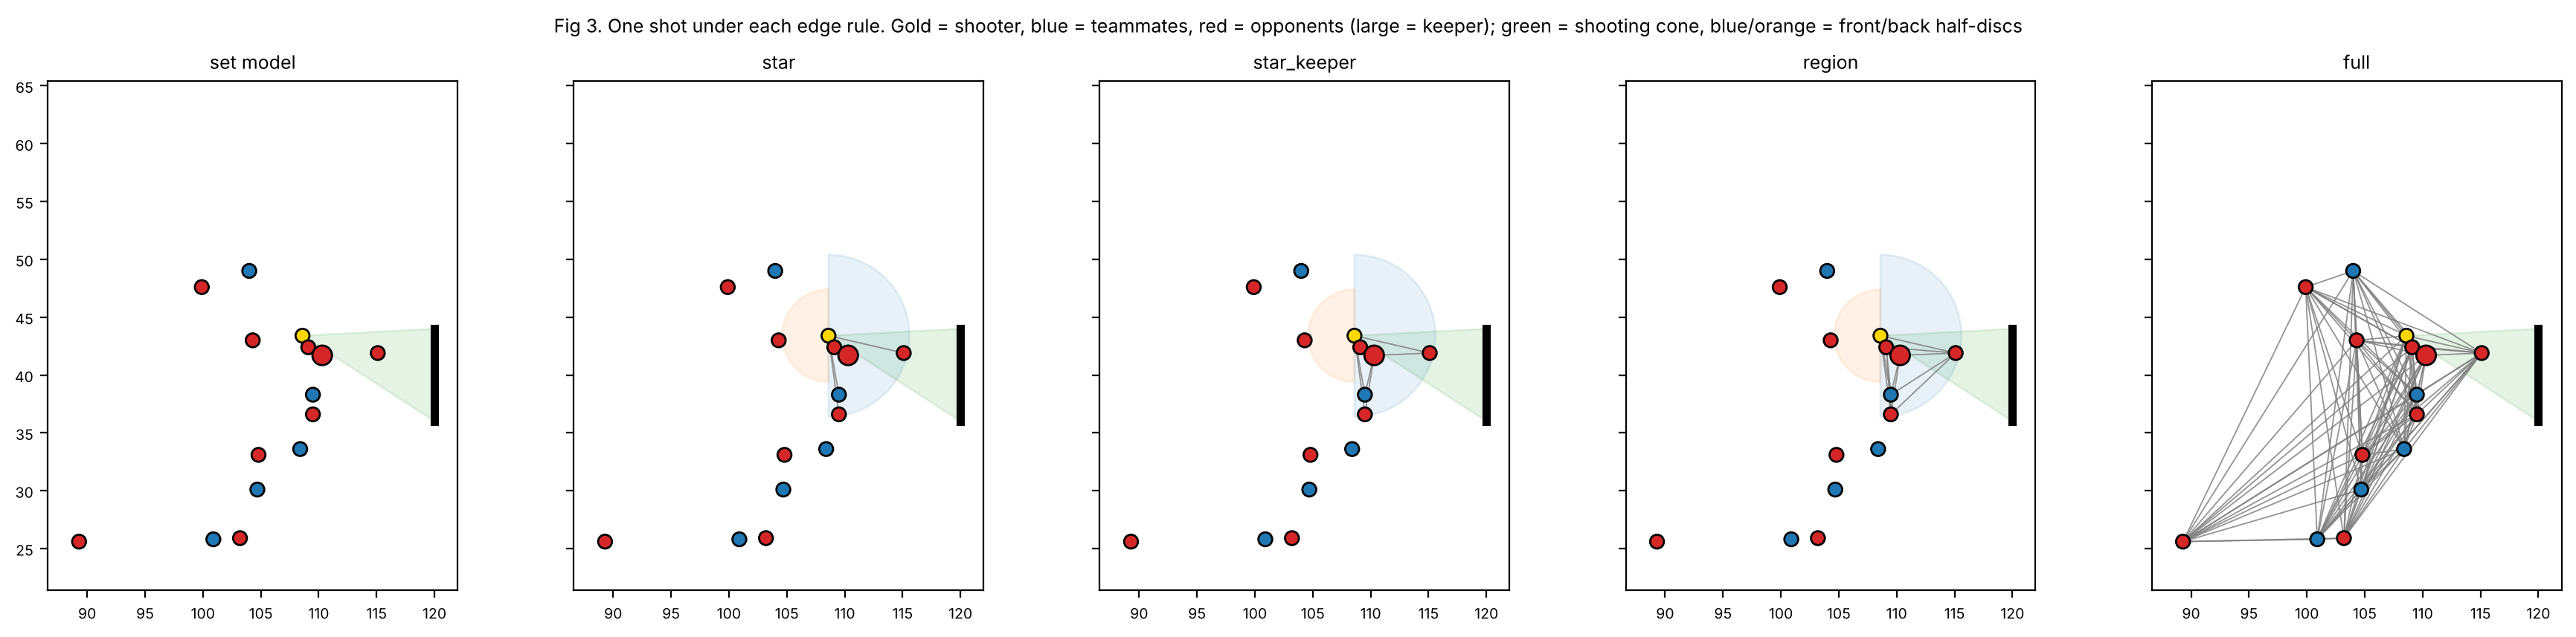

In [6]:
def draw_pitch_shot(ax, i, rule, r_front=7.0, r_back=4.0, node_size=None, title=None):
    a, b = NODE_PTR[i], NODE_PTR[i + 1]
    px, py = POS[a:b, 0], POS[a:b, 1]
    team, kp, sh = TEAM[a:b], KEEPER[a:b], SHOOTER[a:b]
    s = int(np.flatnonzero(sh)[0]); sx, sy = px[s], py[s]
    ax.add_patch(Polygon([[sx, sy], [GOAL_X, POST_L], [GOAL_X, POST_R]], alpha=0.12, color="tab:green"))
    if rule in REGION_RULES:
        ax.add_patch(Wedge((sx, sy), r_front, -90, 90, alpha=0.10, color="tab:blue"))
        ax.add_patch(Wedge((sx, sy), r_back, 90, 270, alpha=0.10, color="tab:orange"))
    es, ed = build_edges(rule, px, py, team, kp, sh, r_front, r_back)
    for u_, v_ in zip(es, ed):
        ax.plot([px[u_], px[v_]], [py[u_], py[v_]], color="grey", lw=0.6, alpha=0.6, zorder=1)
    col = np.where(sh == 1, "gold", np.where(team == 1, "tab:blue", "tab:red"))
    size = node_size if node_size is not None else np.where(kp == 1, 90, 45)
    ax.scatter(px, py, c=col, s=size, edgecolor="k", zorder=3)
    ax.plot([GOAL_X, GOAL_X], [POST_L, POST_R], color="k", lw=4)
    ax.set_title(title or f"{rule}: {len(es)} edges", fontsize=9); ax.set_aspect("equal")
    ax.set_xlim(sx - 22, 122); ax.set_ylim(sy - 22, sy + 22); ax.tick_params(labelsize=7)

EXAMPLE = int(next(i for i in IDX["val"][IN15["val"]] if NCOUNT[i] >= 14 and POS[NODE_PTR[i], 0] > 100))
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2), sharey=True)
for ax, rule in zip(axes, RULES):
    draw_pitch_shot(ax, EXAMPLE, rule, title=f"{'set model' if rule == 'none' else rule}")
fig.suptitle("Fig 3. One shot under each edge rule. Gold = shooter, blue = teammates, red = opponents (large = keeper); "
             "green = shooting cone, blue/orange = front/back half-discs", fontsize=9)
plt.tight_layout(); plt.savefig(FIGURES / "fig03_edge_rules.png", dpi=150); plt.show()

In [7]:
edge_counts = pd.DataFrame({r: {"mean edges per shot": get_store(r).mean_edges,
                                "max edges per shot": int(get_store(r).ecount.max())} for r in RULES}).T
edge_counts.round(1)

  built ('none',): 0.0 directed edges per shot (0s)


  built ('star', 7.0, 4.0): 7.9 directed edges per shot (4s)


  built ('star_keeper', 7.0, 4.0): 13.7 directed edges per shot (4s)


  built ('region', 7.0, 4.0): 22.9 directed edges per shot (5s)


  built ('full',): 189.2 directed edges per shot (1s)


,mean edges per shot,max edges per shot
none,0.0,0.0
star,7.9,30.0
star_keeper,13.7,58.0
region,22.9,240.0
full,189.2,462.0


The number of edges controls the cost of a graph model (Section 7). `full` grows like n² in the number of players,
the region rules grow roughly like n.

## 3. The models

Both models share one code path, so the only difference between them is message passing.

1. **Encode** each player: `h_i = MLP(x_i)`.
2. **Message passing** (graph model only, 2 rounds). For each edge j → i: `m_ji = MLP([h_i, h_j, e_ji])`;
   each player combines its incoming messages with the aggregator `a_i = AGG_j(m_ji)` and updates
   `h_i ← LayerNorm(h_i + MLP([h_i, a_i]))`. Two rounds let information travel two steps,
   e.g. defender → defender → shooter.
3. **Readout**: the shooter's vector, concatenated with a pooled summary of all players `AGG_i(h_i)`, concatenated with
   the shot features (distance, angle, body part, ...). An MLP gives the logit of P(goal).

With 0 rounds this is a **Deep Sets** model: each player is encoded independently and pooled, so the model sees
every player but never how players relate to each other. That is our set model.

**Aggregators** (`AGG`), i.e. how a group of players or messages is summarised:
* `sum`: adds everything up. Sensitive to *how many* players there are (a crowded box gives a big signal).
* `mean`: the average. Ignores the count, describes the "typical" player.
* `max`: the strongest signal per feature. Close to "what does the single most dangerous defender do".
* `attn`: a learned weighted average. The model scores each player and the weights sum to 1, so it can learn
  that a defender in the shooting lane matters more than one 30 yards away.

The same aggregator is used for message passing and for the readout, so the set and graph models are tuned
on equal terms.

In [8]:
def scatter_sum(src, index, n):
    return src.new_zeros((n,) + src.shape[1:]).index_add_(0, index, src)

def scatter_mean(src, index, n):
    cnt = torch.bincount(index, minlength=n).clamp(min=1).to(src.dtype).unsqueeze(1)
    return scatter_sum(src, index, n) / cnt

def scatter_max(src, index, n):
    out = src.new_full((n,) + src.shape[1:], 0.0)
    return out.scatter_reduce(0, index.unsqueeze(1).expand_as(src), src, reduce="amax", include_self=False)

def segment_softmax(score, index, n):
    mx = score.new_full((n,), float("-inf")).scatter_reduce(0, index, score, reduce="amax", include_self=True)
    ex = torch.exp(score - mx[index])
    return ex / (scatter_sum(ex, index, n)[index] + 1e-12)

def aggregate(x, index, n, how, scorer=None):
    if how == "sum":
        return scatter_sum(x, index, n), None
    if how == "mean":
        return scatter_mean(x, index, n), None
    if how == "max":
        return scatter_max(x, index, n), None
    alpha = segment_softmax(scorer(x).squeeze(1), index, n)            # attention
    return scatter_sum(alpha.unsqueeze(1) * x, index, n), alpha

class MPLayer(nn.Module):
    def __init__(self, h, e_dim, aggr):
        super().__init__()
        self.aggr = aggr
        self.msg = nn.Sequential(nn.Linear(2 * h + e_dim, h), nn.ReLU(), nn.Linear(h, h))
        self.upd = nn.Sequential(nn.Linear(2 * h, h), nn.ReLU(), nn.Linear(h, h))
        self.norm = nn.LayerNorm(h)
        self.scorer = nn.Linear(h, 1) if aggr == "attn" else None

    def forward(self, h, src, dst, e):
        if src.numel() == 0:
            agg = torch.zeros_like(h)
        else:
            m = self.msg(torch.cat([h[dst], h[src], e], 1))
            agg, _ = aggregate(m, dst, h.size(0), self.aggr, self.scorer)
        return self.norm(h + self.upd(torch.cat([h, agg], 1)))

class XGNet(nn.Module):
    # rounds = 0 -> set model (Deep Sets); rounds > 0 -> graph model (message passing)
    def __init__(self, node_dim, shot_dim, rounds=2, aggr="sum", hidden=64, edge_dim=4, dropout=0.1):
        super().__init__()
        self.aggr = aggr
        self.enc = nn.Sequential(nn.Linear(node_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
        self.layers = nn.ModuleList([MPLayer(hidden, edge_dim, aggr) for _ in range(rounds)])
        self.pool_scorer = nn.Linear(hidden, 1) if aggr == "attn" else None
        self.head = nn.Sequential(nn.Linear(2 * hidden + shot_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
                                  nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))
        self.last_alpha = None

    def forward(self, b):
        h = self.enc(b.x)
        for layer in self.layers:
            h = layer(h, b.src, b.dst, b.edge_attr)
        pooled, self.last_alpha = aggregate(h, b.node_graph, b.n_graphs, self.aggr, self.pool_scorer)
        return self.head(torch.cat([h[b.is_shooter], pooled, b.u], 1)).squeeze(1)

n_params = lambda m: sum(p.numel() for p in m.parameters())
for feats in ["basic", "engineered"]:
    d = X_FEATS[feats].shape[1]
    print(f"{feats:>10} features ({d}): set model {n_params(XGNet(d, U.shape[1], rounds=0)):,} parameters, "
          f"graph model {n_params(XGNet(d, U.shape[1], rounds=2)):,} parameters")

     basic features (13): set model 17,345 parameters, graph model 67,777 parameters
engineered features (17): set model 17,601 parameters, graph model 68,033 parameters


The graph model has more parameters than the set model (the message and update MLPs). This is reported next to
every result so that a graph win cannot simply be put down to size without checking.

### Correctness tests
* **Permutation invariance:** shuffling the order of players inside a shot must not change the prediction.
* **Batching:** a shot must get the same prediction alone or inside a batch.

In [9]:
def check_model():
    store, idx = get_store("full"), IDX["val"][:8]
    for aggr in ["sum", "mean", "max", "attn"]:
        torch.manual_seed(0)
        model = XGNet(X_FEATS["basic"].shape[1], U.shape[1], rounds=2, aggr=aggr).eval()
        with torch.no_grad():
            b = store.batch(idx, "basic")
            together = model(b)
            alone = torch.cat([model(store.batch(idx[i:i + 1], "basic")) for i in range(len(idx))])
            nc = NCOUNT[idx]
            perm = torch.cat([torch.randperm(int(c)) + int(o) for c, o in zip(nc, np.cumsum(nc) - nc)])
            inv = torch.empty_like(perm); inv[perm] = torch.arange(len(perm))
            b2 = copy.copy(b)
            b2.x, b2.is_shooter, b2.node_graph = b.x[perm], b.is_shooter[perm], b.node_graph[perm]
            b2.src, b2.dst = inv[b.src], inv[b.dst]
            shuffled = model(b2)
        assert torch.allclose(together, alone, atol=1e-4), f"{aggr}: batch vs single mismatch"
        assert torch.allclose(together, shuffled, atol=1e-4), f"{aggr}: not permutation invariant"
    print("OK: predictions do not depend on player order or on batching (sum / mean / max / attn).")

check_model()

OK: predictions do not depend on player order or on batching (sum / mean / max / attn).


## 4. Training and evaluation setup

* **Loss:** binary cross-entropy on the unweighted data. No resampling of goals, because that would distort the
  probabilities and calibration is what makes an xG model useful.
* **Optimiser:** AdamW (lr 1e-3, weight decay 1e-4), batch size 256, gradient clipping.
  **Early stopping** on `val15` log loss (patience 4), best weights restored.
* **Metrics:**
  * **log loss** (main metric): heavily penalises confident wrong predictions. Lower is better.
  * **Brier score**: mean squared error of the probability. Lower is better.
  * **ROC AUC**: how well the model ranks goals above non-goals (ignores calibration). Higher is better.
* **Fairness rule:** any choice that applies to both models (aggregator, features, training data) is tuned for both.
  Graph-only choices (edge rule, region size) are tuned for the graph model only.
* **StatsBomb xG** is shown as a reference ceiling, not a fair opponent: it is trained on far more data.

In [10]:
def metrics(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return {"logloss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p), "auc": roc_auc_score(y, p)}

@torch.no_grad()
def predict(model, store, idx, feats, bs=2048):
    model.eval()
    return torch.cat([torch.sigmoid(model(store.batch(idx[i:i + bs], feats).to(DEVICE))).cpu()
                      for i in range(0, len(idx), bs)]).numpy()

BASE = dict(rule="region", r_front=7.0, r_back=4.0, aggr="sum", feats="basic", train="all", frac=1.0)

def train_indices(cfg, seed=0):
    if cfg["train"] == "1516":
        idx = IDX["train_1516"]
    else:
        idx = IDX["train_all"]
    if cfg["train"] == "all_sub":     # all seasons, subsampled (by match) to the size of the 2015/16 training set
        n_target = len(np.unique(MATCH_IDS[IDX["train_1516"]]))
        keep = np.random.default_rng(123).choice(np.unique(MATCH_IDS[idx]), n_target, replace=False)
        idx = idx[np.isin(MATCH_IDS[idx], keep)]
    if cfg["frac"] < 1.0:             # learning curve: a fraction of the training matches
        m = np.unique(MATCH_IDS[idx])
        keep = np.random.default_rng(1000 + seed).choice(m, max(1, int(cfg["frac"] * len(m))), replace=False)
        idx = idx[np.isin(MATCH_IDS[idx], keep)]
    return idx

def train_model(cfg, seed):
    rounds = 0 if cfg["rule"] == "none" else 2
    store = get_store(cfg["rule"], cfg["r_front"], cfg["r_back"])
    tr, val15 = train_indices(cfg, seed), IDX["val"][IN15["val"]]
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = XGNet(X_FEATS[cfg["feats"]].shape[1], U.shape[1], rounds=rounds, aggr=cfg["aggr"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    lossf = nn.BCEWithLogitsLoss()
    best, best_state, best_ep, bad, ep_times = np.inf, None, 0, 0, []
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); t0 = time.time()
        order = rng.permutation(tr)
        for i in range(0, len(order), 256):
            b = store.batch(order[i:i + 256], cfg["feats"]).to(DEVICE)
            opt.zero_grad()
            lossf(model(b), b.y).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        ep_times.append(time.time() - t0)
        v = metrics(Y[val15].numpy(), predict(model, store, val15, cfg["feats"]))["logloss"]
        if v < best - 1e-5:
            best, best_state, best_ep, bad = v, copy.deepcopy(model.state_dict()), ep, 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    preds = {s: predict(model, store, IDX[s], cfg["feats"]) for s in ["val", "test"]}
    info = dict(best_epoch=best_ep, epochs_run=ep, epoch_time_s=float(np.mean(ep_times)),
                n_train=len(tr), edges_per_shot=store.mean_edges, n_params=n_params(model))
    return model, info, preds

In [11]:
RESULTS, PREDS, MODELS = [], {}, {}
ckey = lambda cfg: tuple(sorted(cfg.items()))

def run(experiment, named_cfgs, seeds=None):
    # Train every configuration (reusing any identical configuration already trained) and return a summary.
    seeds = seeds or TUNE_SEEDS
    for name, cfg in named_cfgs.items():
        for seed in seeds:
            k = (ckey(cfg), seed)
            if k not in PREDS:
                t0 = time.time()
                MODELS[k], info, PREDS[k] = train_model(cfg, seed)
                print(f"  {name:<34} seed {seed}: val15 log loss "
                      f"{metrics(Y[IDX['val'][IN15['val']]].numpy(), PREDS[k]['val'][IN15['val']])['logloss']:.4f}"
                      f"  ({time.time() - t0:.0f}s)")
                RESULTS.append(dict(key=k, **cfg, seed=seed, **info))
            row = next(r for r in RESULTS if r["key"] == k)
            row.setdefault("used_in", set()).add((experiment, name))
    return summary(experiment)

def eval_rows(experiment):
    out = []
    for r in RESULTS:
        for exp, name in r.get("used_in", ()):
            if exp != experiment:
                continue
            p = PREDS[r["key"]]["val"]
            m15 = metrics(Y[IDX["val"][IN15["val"]]].numpy(), p[IN15["val"]])
            out.append(dict(name=name, model="set" if r["rule"] == "none" else "graph", seed=r["seed"],
                            **{f"val15_{k}": v for k, v in m15.items()},
                            epoch_time_s=r["epoch_time_s"], edges_per_shot=r["edges_per_shot"],
                            n_params=r["n_params"], best_epoch=r["best_epoch"], cfg=r["key"][0]))
    return pd.DataFrame(out)

def summary(experiment):
    df = eval_rows(experiment)
    g = df.groupby(["name", "model"], sort=False).agg(
        val15_logloss=("val15_logloss", "mean"), val15_brier=("val15_brier", "mean"), val15_auc=("val15_auc", "mean"),
        epoch_time_s=("epoch_time_s", "mean"), edges_per_shot=("edges_per_shot", "mean"),
        n_params=("n_params", "first"), best_epoch=("best_epoch", "mean"))
    return g.reset_index().sort_values("val15_logloss").reset_index(drop=True)

def best_cfg(experiment, model):
    df = eval_rows(experiment)
    df = df[df["model"] == model].groupby("cfg")["val15_logloss"].mean().sort_values()
    return dict(df.index[0])

SB_VAL15 = metrics(Y[IDX["val"][IN15["val"]]].numpy(), BENCH[IDX["val"][IN15["val"]]])["logloss"]

def plot_experiment(experiment, title, fig_name):
    s = summary(experiment)
    fig, ax = plt.subplots(figsize=(7, 0.42 * len(s) + 1.2))
    colours = s["model"].map({"set": "tab:orange", "graph": "tab:blue"})
    ax.barh(s["name"], s["val15_logloss"], color=colours)
    lo = min(s["val15_logloss"].min(), SB_VAL15)
    ax.set_xlim(lo - 0.004, s["val15_logloss"].max() + 0.003)
    ax.axvline(SB_VAL15, color="k", ls="--", lw=1, label=f"StatsBomb xG ({SB_VAL15:.4f})")
    for y_, v in enumerate(s["val15_logloss"]):
        ax.text(v, y_, f" {v:.4f}", va="center", fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel("validation log loss, 2015/16 matches (lower is better)")
    ax.set_title(title, fontsize=10)
    ax.scatter([], [], c="tab:orange", marker="s", label="set"); ax.scatter([], [], c="tab:blue", marker="s", label="graph")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35 / (0.42 * len(s) + 1.2) * 3), ncol=3, fontsize=8, frameon=False)
    plt.tight_layout(); plt.savefig(FIGURES / fig_name, dpi=150); plt.show()

## 5. Experiments (tuning on the validation set)

Each experiment changes **one** thing and keeps the best setting so far (a greedy chain:
edge rule → region size → aggregation → features → training data). This is much cheaper than trying every
combination, but it can miss interactions between settings. The test set is not touched until Section 6.

How to read the figures: bars are validation log loss on 2015/16 matches (lower is better), orange = set model,
blue = graph model, dashed line = StatsBomb xG. Differences in the third decimal place are small; seed-to-seed noise
is measured in Section 6.

### 5.1 Edge rule: does connecting players help, and which connections?
The set model is the reference. If any graph rule beats it, relations between players carry information that
the individual player features do not.

  set model                          seed 0: val15 log loss 0.2682  (9s)


  graph: star                        seed 0: val15 log loss 0.2701  (29s)


  graph: star + keeper               seed 0: val15 log loss 0.2661  (70s)


  graph: region                      seed 0: val15 log loss 0.2681  (81s)


  graph: full                        seed 0: val15 log loss 0.2701  (220s)


,name,model,val15_logloss,val15_brier,val15_auc,epoch_time_s,edges_per_shot,n_params,best_epoch
0,graph: star + keeper,graph,0.2661,0.0762,0.8011,2.9075,13.7057,67777,19.0
1,graph: region,graph,0.2681,0.0767,0.8003,3.8676,22.8904,67777,16.0
2,set model,set,0.2682,0.0770,0.7982,0.5364,0.0000,17345,9.0
3,graph: full,graph,0.2701,0.0773,0.7937,20.2016,189.1748,67777,6.0
4,graph: star,graph,0.2701,0.0772,0.7930,2.1304,7.8548,67777,9.0


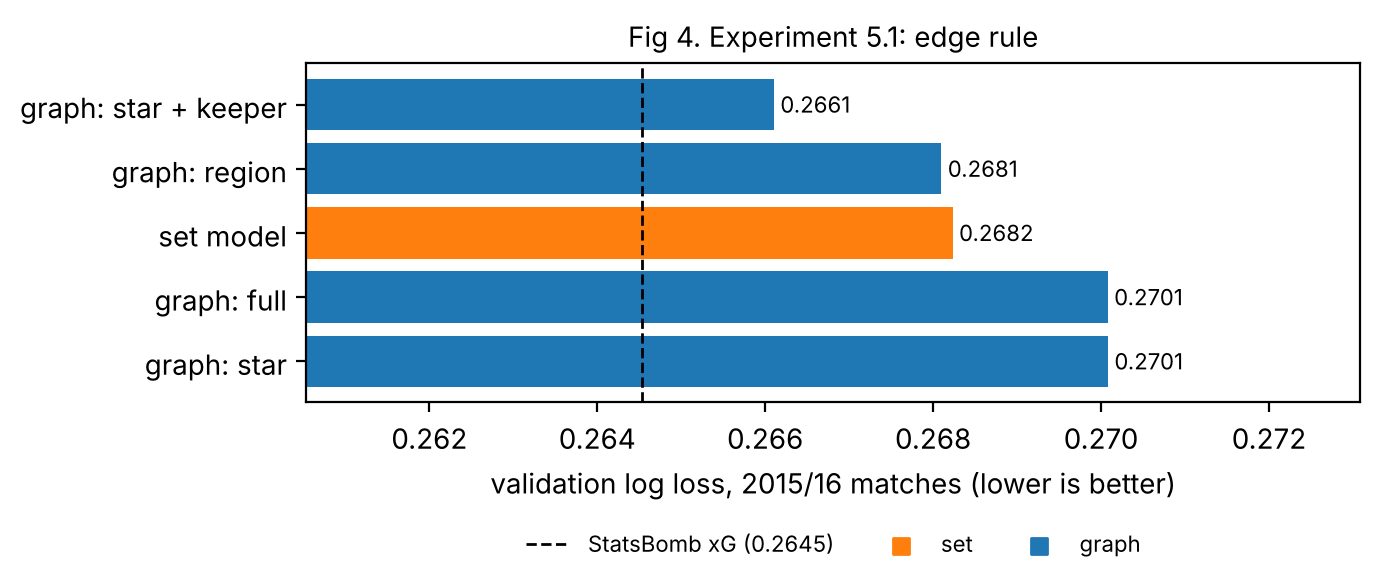

best graph rule: star_keeper


In [12]:
E1 = {"set model": {**BASE, "rule": "none"},
      "graph: star": {**BASE, "rule": "star"},
      "graph: star + keeper": {**BASE, "rule": "star_keeper"},
      "graph: region": {**BASE, "rule": "region"},
      "graph: full": {**BASE, "rule": "full"}}
display(run("5.1 edge rule", E1).round(4))
plot_experiment("5.1 edge rule", "Fig 4. Experiment 5.1: edge rule", "fig04_exp_edge_rule.png")
BEST = {"set": best_cfg("5.1 edge rule", "set"), "graph": best_cfg("5.1 edge rule", "graph")}
print("best graph rule:", BEST["graph"]["rule"])

`edges_per_shot` and `epoch_time_s` show the cost of each rule. These are used again in Section 7.

### 5.2 Region size: how far around the shooter should connections reach?
Graph-only. We try a small, the default and a large region on the best of the region-based rules. Small regions give
cheaper graphs; large ones move towards the `full` rule.

  built ('star_keeper', 5.0, 3.0): 10.9 directed edges per shot (5s)


  star_keeper small (5 / 3 yd)       seed 0: val15 log loss 0.2678  (70s)


  built ('star_keeper', 10.0, 6.0): 18.9 directed edges per shot (4s)


  star_keeper large (10 / 6 yd)      seed 0: val15 log loss 0.2705  (49s)


,name,model,val15_logloss,val15_brier,val15_auc,epoch_time_s,edges_per_shot,n_params,best_epoch
0,star_keeper default (7 / 4 yd),graph,0.2661,0.0762,0.8011,2.9075,13.7057,67777,19.0
1,star_keeper small (5 / 3 yd),graph,0.2678,0.0765,0.7971,2.5100,10.9495,67777,22.0
2,star_keeper large (10 / 6 yd),graph,0.2705,0.0772,0.7922,3.2838,18.9153,67777,9.0


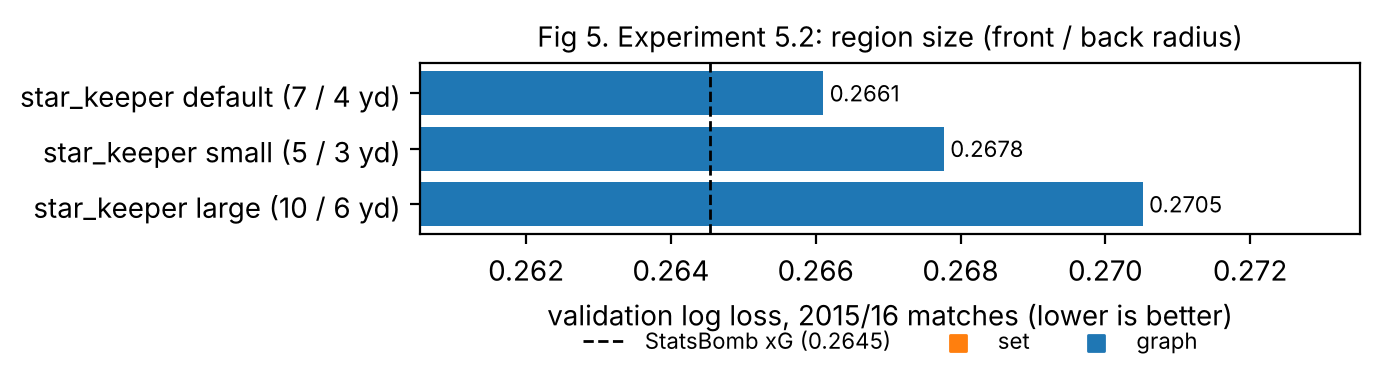

graph model so far: {'aggr': 'sum', 'feats': 'basic', 'frac': 1.0, 'r_back': 4.0, 'r_front': 7.0, 'rule': 'star_keeper', 'train': 'all'}


In [13]:
E1_sum = summary("5.1 edge rule")
region_rule = E1_sum[E1_sum["name"].isin(["graph: star", "graph: star + keeper", "graph: region"])].iloc[0]["name"]
region_rule = {"graph: star": "star", "graph: star + keeper": "star_keeper", "graph: region": "region"}[region_rule]
E2 = {f"{region_rule} small (5 / 3 yd)": {**BEST["graph"], "rule": region_rule, "r_front": 5.0, "r_back": 3.0},
      f"{region_rule} default (7 / 4 yd)": {**BEST["graph"], "rule": region_rule, "r_front": 7.0, "r_back": 4.0},
      f"{region_rule} large (10 / 6 yd)": {**BEST["graph"], "rule": region_rule, "r_front": 10.0, "r_back": 6.0}}
if BEST["graph"]["rule"] == "full":
    E2["full (no region)"] = BEST["graph"]
display(run("5.2 region size", E2).round(4))
plot_experiment("5.2 region size", "Fig 5. Experiment 5.2: region size (front / back radius)", "fig05_exp_region.png")
BEST["graph"] = best_cfg("5.2 region size", "graph")
print("graph model so far:", BEST["graph"])

### 5.3 Aggregation: how should a group of players be summarised?
Applies to both models (fairness rule). For the set model it is how the players are pooled; for the graph model it is
also how each player combines its incoming messages. See Section 3 for what each aggregator means.

  set: mean                          seed 0: val15 log loss 0.2684  (12s)


  set: max                           seed 0: val15 log loss 0.2652  (13s)


  set: attn                          seed 0: val15 log loss 0.2674  (11s)


  graph: mean                        seed 0: val15 log loss 0.2671  (46s)


  graph: max                         seed 0: val15 log loss 0.2653  (37s)


  graph: attn                        seed 0: val15 log loss 0.2678  (32s)


,name,model,val15_logloss,val15_brier,val15_auc,epoch_time_s,edges_per_shot,n_params,best_epoch
0,set: max,set,0.2652,0.0760,0.8052,0.7025,0.0000,17345,14.0
1,graph: max,graph,0.2653,0.0760,0.8037,3.5557,13.7057,67777,6.0
2,graph: sum,graph,0.2661,0.0762,0.8011,2.9075,13.7057,67777,19.0
3,graph: mean,graph,0.2671,0.0765,0.8003,2.7265,13.7057,67777,12.0
4,set: attn,set,0.2674,0.0767,0.7994,0.5989,0.0000,17410,13.0
5,graph: attn,graph,0.2678,0.0767,0.7994,3.1024,13.7057,67972,6.0
6,set: sum,set,0.2682,0.0770,0.7982,0.5364,0.0000,17345,9.0
7,set: mean,set,0.2684,0.0771,0.7992,0.5102,0.0000,17345,19.0


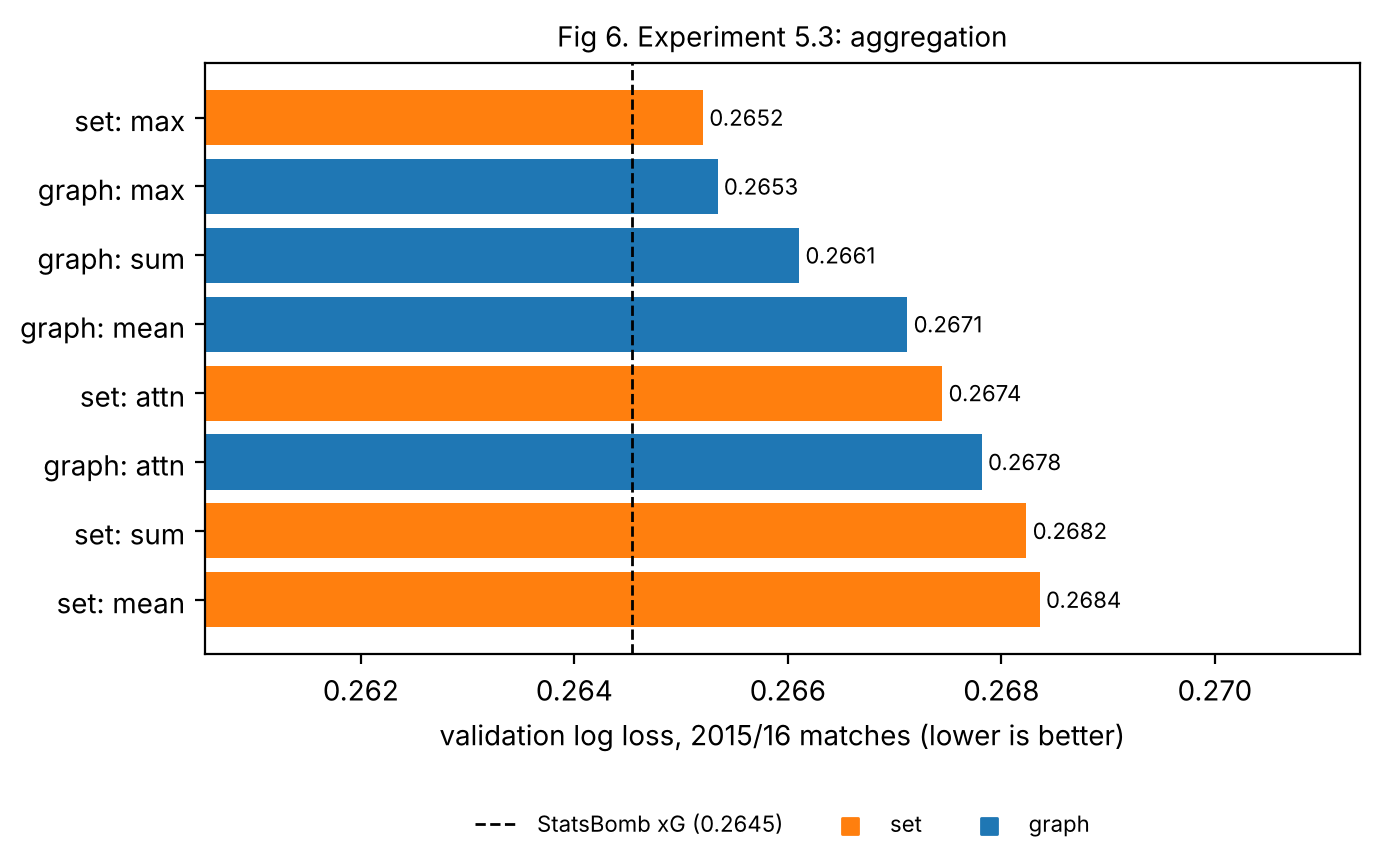

set: max | graph: max


In [14]:
E3 = {}
for m in ["set", "graph"]:
    for a in ["sum", "mean", "max", "attn"]:
        E3[f"{m}: {a}"] = {**BEST[m], "aggr": a}
display(run("5.3 aggregation", E3).round(4))
plot_experiment("5.3 aggregation", "Fig 6. Experiment 5.3: aggregation", "fig06_exp_aggregation.png")
BEST = {m: best_cfg("5.3 aggregation", m) for m in ["set", "graph"]}
print("set:", BEST["set"]["aggr"], "| graph:", BEST["graph"]["aggr"])

### 5.4 Engineered features: does hand-made geometry help, or can the network learn it?
Both models, with and without the four engineered player features (distance to the shot line, in cone, distance to
the edge of the cone, share of the goal blocked). If the graph model gains less from them than the set model, it is
learning some of that geometry itself from the edges.

  set: basic + engineered            seed 0: val15 log loss 0.2589  (9s)


  graph: basic + engineered          seed 0: val15 log loss 0.2599  (36s)


,name,model,val15_logloss,val15_brier,val15_auc,epoch_time_s,edges_per_shot,n_params,best_epoch
0,set: basic + engineered,set,0.2589,0.0744,0.8158,0.6976,0.0000,17601,9.0
1,graph: basic + engineered,graph,0.2599,0.0745,0.8132,3.4378,13.7057,68033,6.0
2,set: basic,set,0.2652,0.0760,0.8052,0.7025,0.0000,17345,14.0
3,graph: basic,graph,0.2653,0.0760,0.8037,3.5557,13.7057,67777,6.0


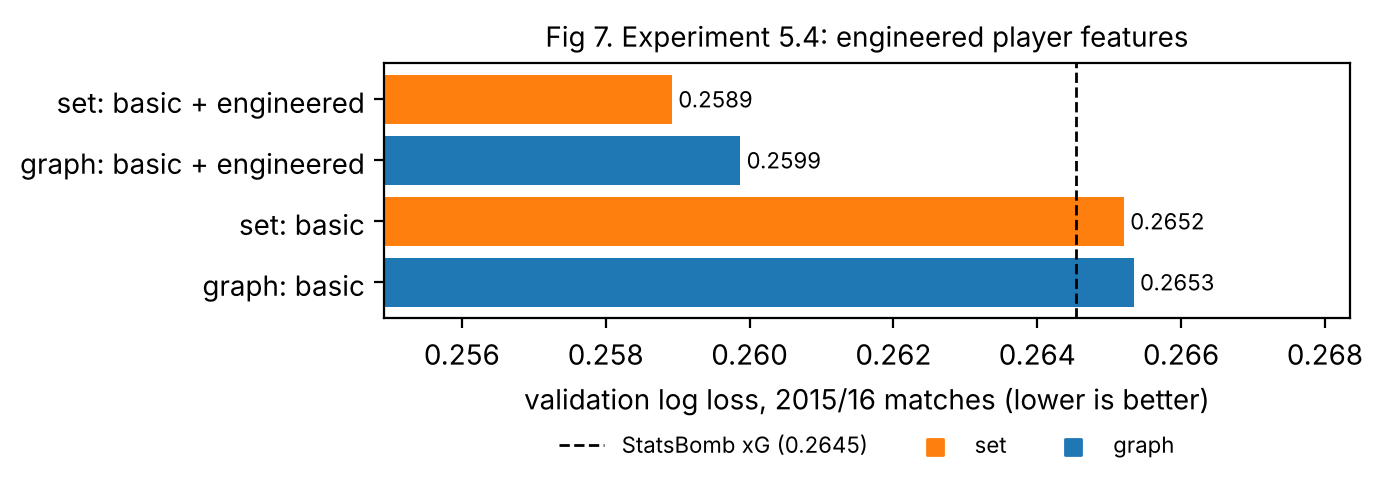

log loss improvement from engineered features: {'set': np.float64(0.0063), 'graph': np.float64(0.0055)}


In [15]:
E4 = {}
for m in ["set", "graph"]:
    E4[f"{m}: basic"] = {**BEST[m], "feats": "basic"}
    E4[f"{m}: basic + engineered"] = {**BEST[m], "feats": "engineered"}
s4 = run("5.4 features", E4)
display(s4.round(4))
plot_experiment("5.4 features", "Fig 7. Experiment 5.4: engineered player features", "fig07_exp_features.png")
gain = {m: s4.set_index("name").loc[f"{m}: basic", "val15_logloss"] - s4.set_index("name").loc[f"{m}: basic + engineered", "val15_logloss"]
        for m in ["set", "graph"]}
print("log loss improvement from engineered features:", {k: round(v, 4) for k, v in gain.items()})
BEST = {m: best_cfg("5.4 features", m) for m in ["set", "graph"]}

### 5.5 Training data: more data vs biased data
Single-club seasons add about 40% more shots, but every one of those matches contains the same, usually dominant,
team. We train on three sets and evaluate on the unbiased 2015/16 validation matches:

* **all seasons**: everything;
* **2015/16 only**: the four complete seasons;
* **all seasons, same size**: all seasons subsampled (by match) to the size of the 2015/16 set.

Comparing *2015/16 only* with *all seasons, same size* separates **which** matches we train on from **how many**.

  set: 2015/16 only                  seed 0: val15 log loss 0.2607  (6s)


  set: all seasons, same size        seed 0: val15 log loss 0.2593  (8s)


  graph: 2015/16 only                seed 0: val15 log loss 0.2634  (20s)


  graph: all seasons, same size      seed 0: val15 log loss 0.2610  (35s)


,name,model,val15_logloss,val15_brier,val15_auc,epoch_time_s,edges_per_shot,n_params,best_epoch
0,set: all seasons,set,0.2589,0.0744,0.8158,0.6976,0.0000,17601,9.0
1,"set: all seasons, same size",set,0.2593,0.0747,0.8156,0.4982,0.0000,17601,12.0
2,graph: all seasons,graph,0.2599,0.0745,0.8132,3.4378,13.7057,68033,6.0
3,set: 2015/16 only,set,0.2607,0.0749,0.8120,0.4711,0.0000,17601,8.0
4,"graph: all seasons, same size",graph,0.2610,0.0749,0.8128,2.3913,13.7057,68033,10.0
5,graph: 2015/16 only,graph,0.2634,0.0754,0.8062,2.4091,13.7057,68033,4.0


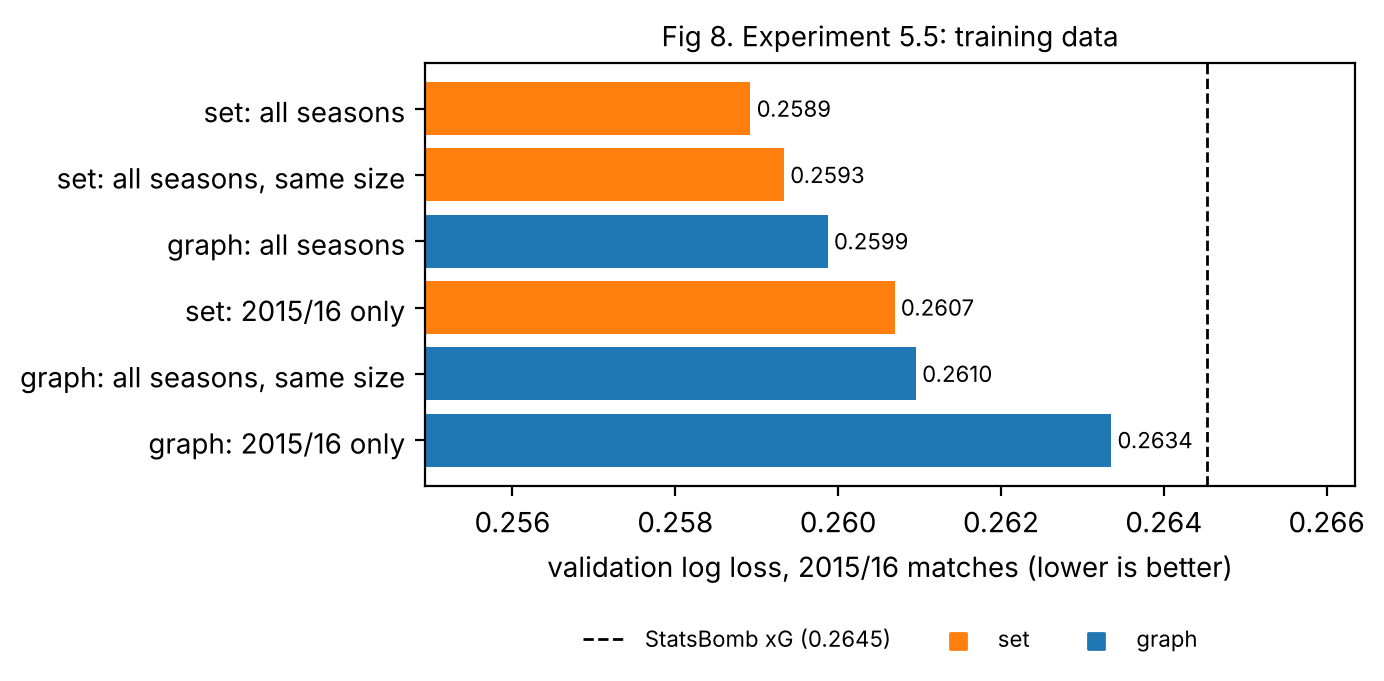

In [16]:
E5 = {}
for m in ["set", "graph"]:
    for name, t in [("all seasons", "all"), ("2015/16 only", "1516"), ("all seasons, same size", "all_sub")]:
        E5[f"{m}: {name}"] = {**BEST[m], "train": t}
display(run("5.5 training data", E5).round(4))
plot_experiment("5.5 training data", "Fig 8. Experiment 5.5: training data", "fig08_exp_training_data.png")

**Do models under-predict the focus club?** On the single-club validation matches we compare actual goals with
the summed xG, separately for the focus club and its opponents. A positive `goals − xG` means the team scored more
than the model expected (finishing quality, or a bias the model has not learnt). StatsBomb xG is the reference.

goals − xG (positive = scored more than expected):


,shots,goals,StatsBomb,"set, trained on all","set, trained on 2015/16","graph, trained on all","graph, trained on 2015/16"
group,,,,,,,
2015/16 matches (all teams),5521,556,51.4,32.200001,-8.500000,19.400000,-31.900000
single-club: focus club,1550,252,69.4,55.400002,47.599998,56.700001,45.700001
single-club: opponents,938,66,-13.2,-15.800000,-22.200001,-18.799999,-27.500000


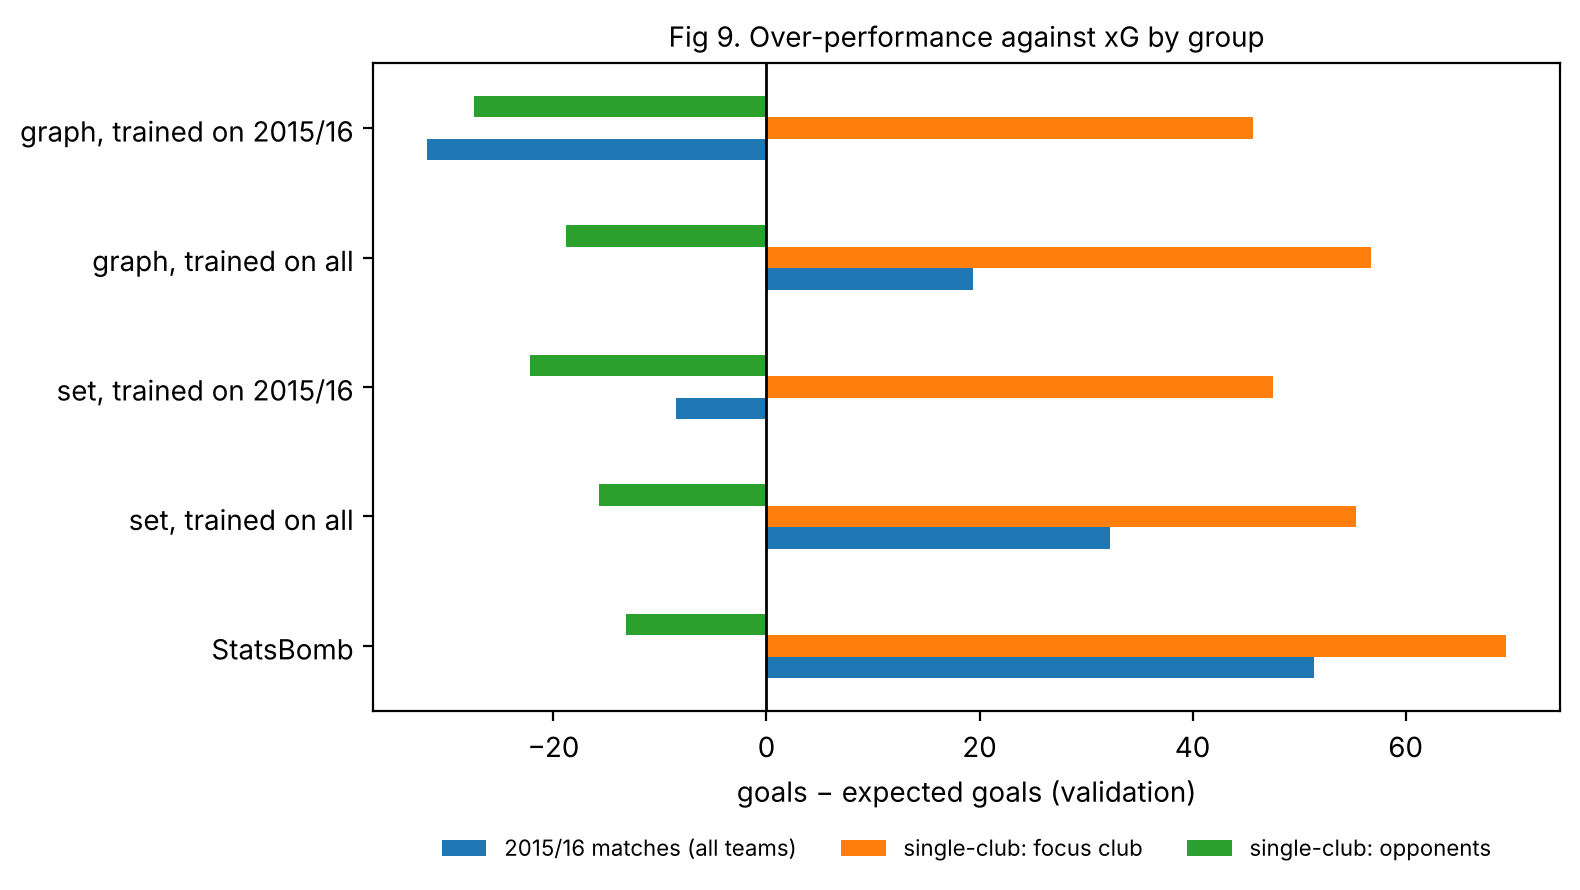

In [17]:
val_idx = IDX["val"]
club = ~IN15["val"]
focus = shot_df["is_focus_team"].values[val_idx] == 1
rows = []
for group, mask in [("2015/16 matches (all teams)", IN15["val"]), ("single-club: focus club", club & focus),
                    ("single-club: opponents", club & ~focus)]:
    r = {"group": group, "shots": int(mask.sum()), "goals": int(Y[val_idx][mask].sum())}
    r["StatsBomb"] = r["goals"] - BENCH[val_idx][mask].sum()
    for m in ["set", "graph"]:
        for tname, t in [("all", "all"), ("2015/16", "1516")]:
            p = PREDS[(ckey({**BEST[m], "train": t}), TUNE_SEEDS[0])]["val"]
            r[f"{m}, trained on {tname}"] = r["goals"] - p[mask].sum()
    rows.append(r)
over = pd.DataFrame(rows).set_index("group")
print("goals − xG (positive = scored more than expected):")
display(over.round(1))

ax = over.drop(columns=["shots", "goals"]).T.plot.barh(figsize=(8, 4.6))
ax.axvline(0, color="k", lw=1); ax.set_xlabel("goals − expected goals (validation)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8, frameon=False)
ax.set_title("Fig 9. Over-performance against xG by group", fontsize=10)
plt.tight_layout(); plt.savefig(FIGURES / "fig09_focus_club_overperformance.png", dpi=150); plt.show()

BEST = {m: best_cfg("5.5 training data", m) for m in ["set", "graph"]}

### 5.6 Chosen configurations
These two configurations go to the final test.

In [18]:
chosen = pd.DataFrame(BEST).T[["rule", "r_front", "r_back", "aggr", "feats", "train"]]
chosen.loc["set", ["r_front", "r_back"]] = "–"     # region size does not apply to the set model
chosen.index.name = "model"
display(chosen)
pd.DataFrame([{**eval_rows(e).drop(columns="cfg").assign(experiment=e).iloc[i].to_dict()}
              for e in ["5.1 edge rule", "5.2 region size", "5.3 aggregation", "5.4 features", "5.5 training data"]
              for i in range(len(eval_rows(e)))]).to_csv(RESULTS_DIR / "experiments.csv", index=False)

,rule,r_front,r_back,aggr,feats,train
model,,,,,,
set,none,–,–,max,engineered,all
graph,star_keeper,7.0,4.0,max,engineered,all


## 6. Final test: set vs graph

The chosen set and graph configurations are trained with three seeds each (seed 0 is reused from the experiments,
since it is an identical run) and evaluated **once** on the test matches.
* Headline: **test15**, the held-out 2015/16 matches. Single-club test matches and all test matches are shown too.
* Each model's prediction is the average over its three seeds (a small ensemble); the seed spread shows how much
  of a difference is just noise.
* **Paired bootstrap over matches:** resample test matches with replacement 2,000 times and recompute the difference
  in log loss. Matches, not shots, are resampled because shots in the same match are not independent.
  If the 95% interval excludes 0, the difference is unlikely to be noise.

In [19]:
FINAL = {"set": BEST["set"], "graph": BEST["graph"]}
run("6 final", {f"{m} (final)": cfg for m, cfg in FINAL.items()}, seeds=FINAL_SEEDS)

y_test, t15 = Y[IDX["test"]].numpy(), IN15["test"]
P = {m: np.mean([PREDS[(ckey(cfg), s)]["test"] for s in FINAL_SEEDS], axis=0) for m, cfg in FINAL.items()}
P["StatsBomb xG"] = BENCH[IDX["test"]].astype(float)

table = []
for group, mask in [("test15 (headline)", t15), ("test single-club", ~t15), ("test all", np.ones_like(t15))]:
    for m, p in P.items():
        row = {"test set": group, "model": m, **metrics(y_test[mask], p[mask])}
        if m in FINAL:   # seed spread
            per_seed = [metrics(y_test[mask], PREDS[(ckey(FINAL[m]), s)]["test"][mask])["logloss"] for s in FINAL_SEEDS]
            row["logloss sd over seeds"] = np.std(per_seed)
        table.append(row)
final = pd.DataFrame(table).set_index(["test set", "model"])
display(final.round(4))
final.to_csv(RESULTS_DIR / "final_test.csv")

  set (final)                        seed 1: val15 log loss 0.2594  (12s)


  set (final)                        seed 2: val15 log loss 0.2597  (10s)


  graph (final)                      seed 1: val15 log loss 0.2601  (61s)


  graph (final)                      seed 2: val15 log loss 0.2609  (51s)


logloss   brier     auc  logloss sd over seeds
test set          model                                                       
test15 (headline) set            0.2380  0.0670  0.8214                 0.0002
                  graph          0.2379  0.0670  0.8211                 0.0001
                  StatsBomb xG   0.2389  0.0665  0.8193                    NaN
test single-club  set            0.2913  0.0852  0.8098                 0.0004
                  graph          0.2909  0.0851  0.8122                 0.0006
                  StatsBomb xG   0.2973  0.0862  0.8005                    NaN
test all          set            0.2535  0.0723  0.8185                 0.0002
                  graph          0.2533  0.0722  0.8192                 0.0002
                  StatsBomb xG   0.2559  0.0723  0.8141                    NaN

In [20]:
def paired_bootstrap(match_ids, y, p_a, p_b, n_boot=2000, seed=0):
    # mean of logloss(A) - logloss(B) with a 95% interval; negative means A is better
    pa, pb = np.clip(p_a, 1e-7, 1 - 1e-7), np.clip(p_b, 1e-7, 1 - 1e-7)
    d = -(y * np.log(pa) + (1 - y) * np.log(1 - pa)) + (y * np.log(pb) + (1 - y) * np.log(1 - pb))
    g = pd.DataFrame({"m": match_ids, "d": d}).groupby("m")["d"].agg(["sum", "count"])
    s, c = g["sum"].values, g["count"].values
    idx = np.random.default_rng(seed).integers(0, len(s), (n_boot, len(s)))
    boot = s[idx].sum(1) / c[idx].sum(1)
    return d.mean(), np.percentile(boot, [2.5, 97.5]), boot

mt = MATCH_IDS[IDX["test"]][t15]
boot_rows, boots = [], {}
for a, b in [("graph", "set"), ("graph", "StatsBomb xG"), ("set", "StatsBomb xG")]:
    m, (lo, hi), boots[(a, b)] = paired_bootstrap(mt, y_test[t15], P[a][t15], P[b][t15])
    verdict = "no clear difference" if lo < 0 < hi else (f"{a} better" if m < 0 else f"{b} better")
    boot_rows.append({"comparison": f"{a} − {b}", "log loss difference": m, "95% CI low": lo, "95% CI high": hi,
                      "verdict": verdict})
boot_df = pd.DataFrame(boot_rows).set_index("comparison")
display(boot_df.round(4))
boot_df.to_csv(RESULTS_DIR / "final_bootstrap.csv")

,log loss difference,95% CI low,95% CI high,verdict
comparison,,,,
graph − set,-0.0001,-0.0011,0.0010,no clear difference
graph − StatsBomb xG,-0.0010,-0.0051,0.0029,no clear difference
set − StatsBomb xG,-0.0009,-0.0052,0.0030,no clear difference


**Fig 10** shows the two things that matter for an xG model: how well it **ranks** shots (ROC curve, left) and whether
its probabilities are **calibrated** (right: within each band of predicted xG, the observed goal rate should equal the
predicted xG, i.e. points on the diagonal).

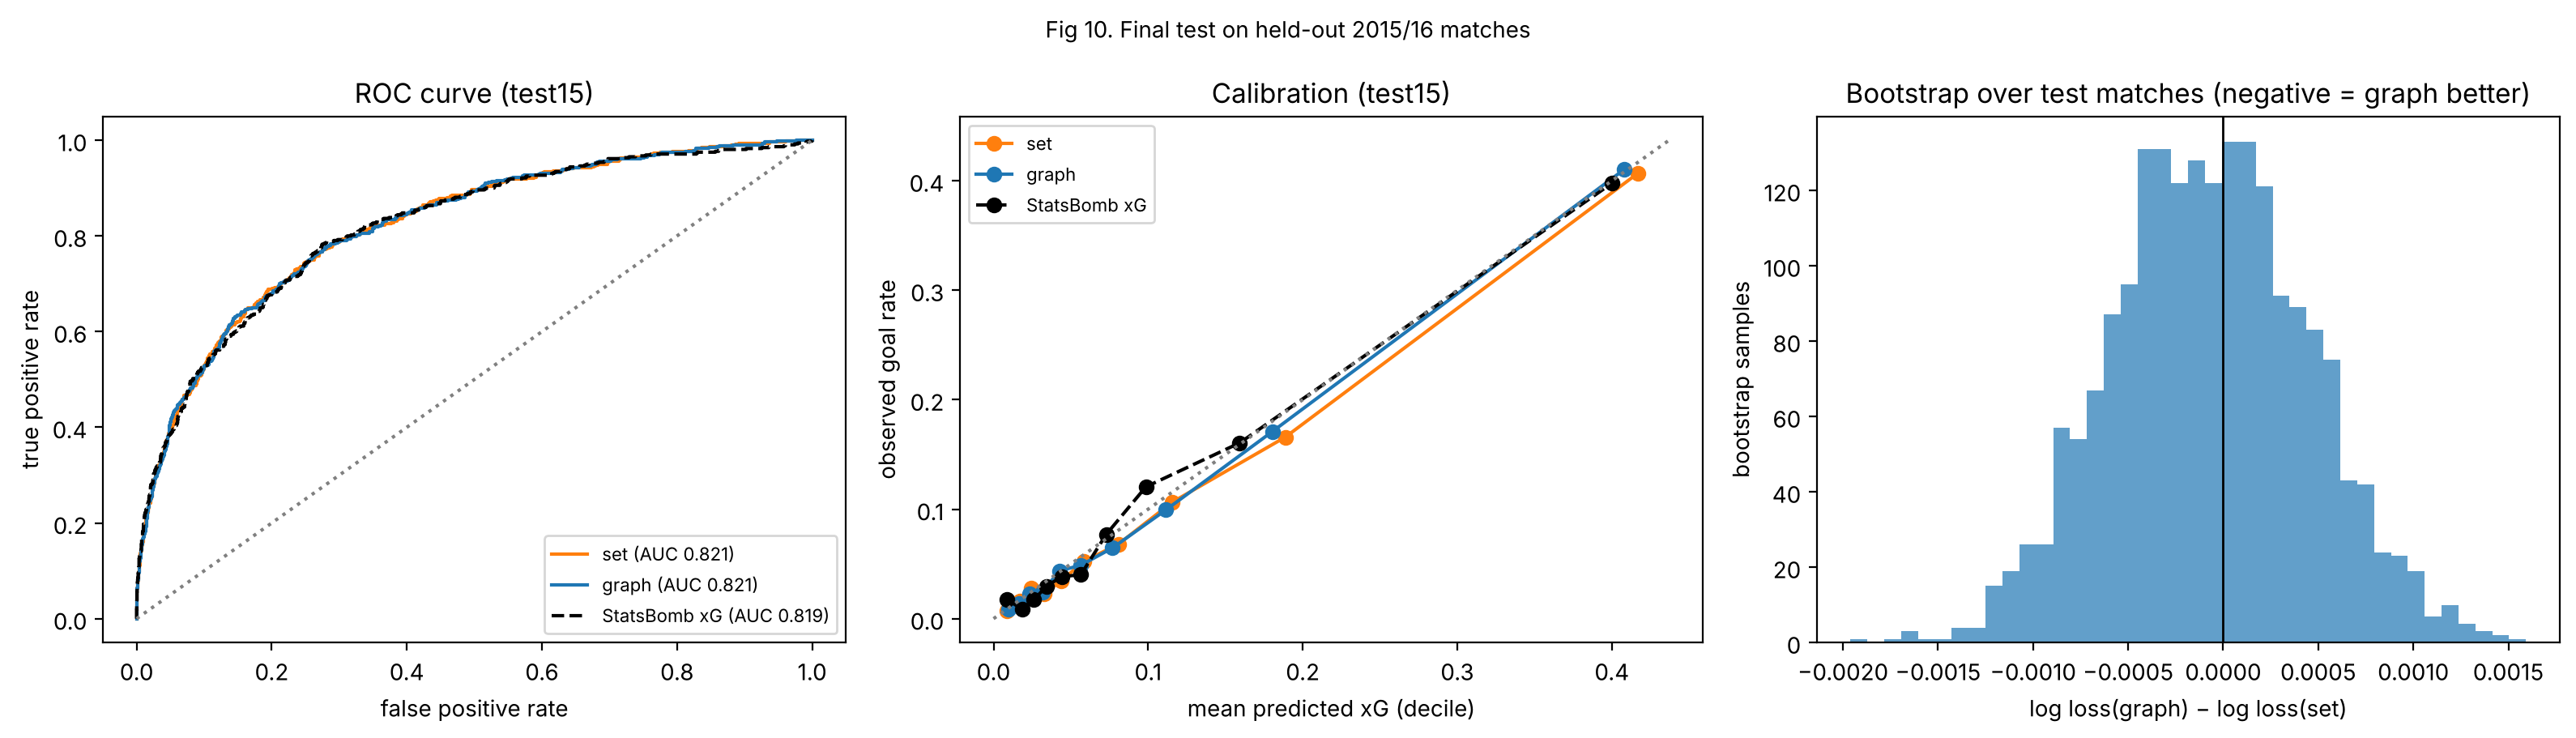

In [21]:
def calib(y, p, bins=10):
    q = pd.qcut(p, bins, duplicates="drop")
    d = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True).agg(p=("p", "mean"), y=("y", "mean"))
    return d["p"].values, d["y"].values

styles = {"set": ("tab:orange", "-"), "graph": ("tab:blue", "-"), "StatsBomb xG": ("k", "--")}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for m, p in P.items():
    c, ls = styles[m]
    fpr, tpr, _ = roc_curve(y_test[t15], p[t15])
    ax[0].plot(fpr, tpr, color=c, ls=ls, label=f"{m} (AUC {roc_auc_score(y_test[t15], p[t15]):.3f})")
    cx, cy = calib(y_test[t15], p[t15])
    ax[1].plot(cx, cy, marker="o", color=c, ls=ls, label=m)
ax[0].plot([0, 1], [0, 1], ":", color="grey"); ax[0].set(xlabel="false positive rate", ylabel="true positive rate",
                                                           title="ROC curve (test15)"); ax[0].legend(fontsize=8)
mx = ax[1].get_xlim()[1]
ax[1].plot([0, mx], [0, mx], ":", color="grey"); ax[1].set(xlabel="mean predicted xG (decile)", ylabel="observed goal rate",
                                                            title="Calibration (test15)"); ax[1].legend(fontsize=8)
ax[2].hist(boots[("graph", "set")], bins=40, color="tab:blue", alpha=0.7)
ax[2].axvline(0, color="k", lw=1)
ax[2].set(xlabel="log loss(graph) − log loss(set)", ylabel="bootstrap samples",
          title="Bootstrap over test matches (negative = graph better)")
fig.suptitle("Fig 10. Final test on held-out 2015/16 matches", fontsize=10)
plt.tight_layout(); plt.savefig(FIGURES / "fig10_final_test.png", dpi=150); plt.show()

**Fig 11: where the models disagree.** The test15 shots on which the set and graph models differ most. These show
what kind of situation the extra relational information changes.

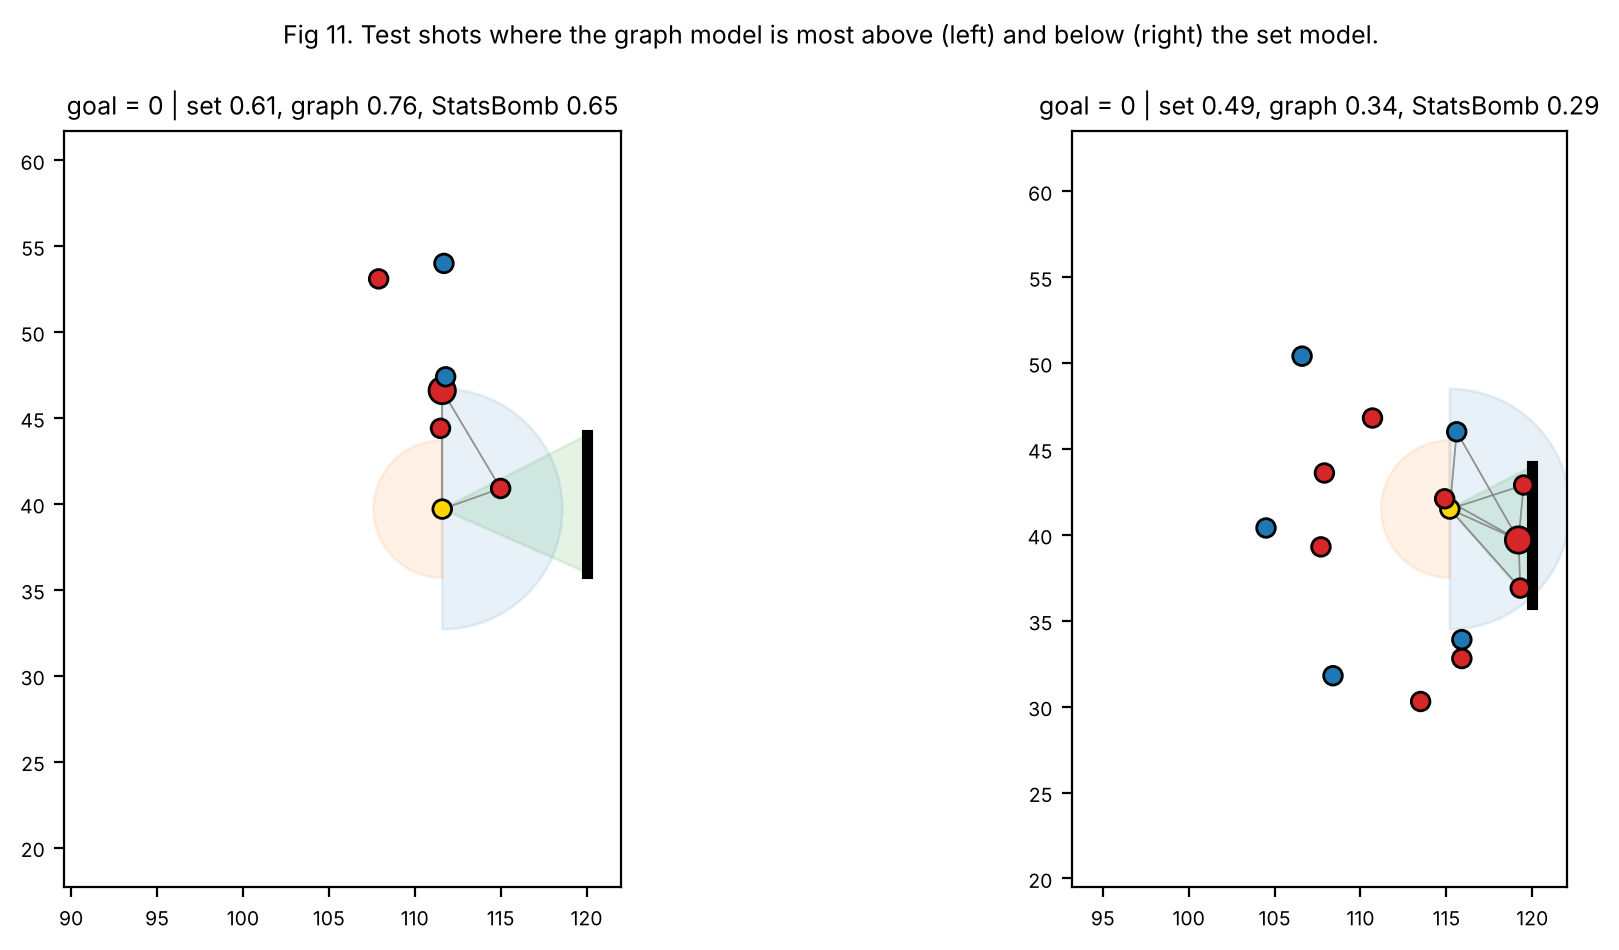

In [22]:
test15_idx = IDX["test"][t15]
diff = P["graph"][t15] - P["set"][t15]
picks = [np.argmax(diff), np.argmin(diff)]
graph_cfg = FINAL["graph"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, j in zip(axes, picks):
    i = int(test15_idx[j])
    size = None
    if graph_cfg["aggr"] == "attn":   # show the graph model's readout attention as node size
        model = MODELS[(ckey(graph_cfg), FINAL_SEEDS[0])].eval()
        with torch.no_grad():
            model(get_store(graph_cfg["rule"], graph_cfg["r_front"], graph_cfg["r_back"]).batch([i], graph_cfg["feats"]))
        size = 40 + 900 * model.last_alpha.numpy()
    draw_pitch_shot(ax, i, graph_cfg["rule"], graph_cfg["r_front"], graph_cfg["r_back"], node_size=size,
                    title=f"goal = {int(Y[i])} | set {P['set'][t15][j]:.2f}, graph {P['graph'][t15][j]:.2f}, "
                          f"StatsBomb {BENCH[i]:.2f}")
note = " Node size = graph model's attention weight." if graph_cfg["aggr"] == "attn" else ""
fig.suptitle("Fig 11. Test shots where the graph model is most above (left) and below (right) the set model." + note,
             fontsize=9)
plt.tight_layout(); plt.savefig(FIGURES / "fig11_disagreements.png", dpi=150); plt.show()

pd.DataFrame({"shot_id": shot_df["shot_id"].values[IDX["test"]], "match_id": MATCH_IDS[IDX["test"]],
              "subset_1516": t15.astype(int), "is_goal": y_test,
              "p_set": P["set"], "p_graph": P["graph"], "p_statsbomb": P["StatsBomb xG"]}
             ).to_csv(RESULTS_DIR / "final_test_predictions.csv", index=False)

## 7. Scaling: what if there were 1000× more data?

No larger StatsBomb freeze-frame dataset is openly available, so we measure how the **cost** grows with data
volume on this laptop and extrapolate. Four measurements, all on the two final configurations:

1. **Learning curve:** train on 10 / 25 / 50 / 100% of the training matches. Does time grow linearly? Is accuracy still improving?
2. **Synthetic volume:** time one epoch on ×1, ×2, ×5, ×10 copies of the training graphs. The cost of a batch depends only on the
   number of nodes and edges, not on whether the shots are new, so copies give an honest timing.
3. **Cost per edge rule:** time against edges per shot (from Experiment 5.1).
4. **Parallelism:** the same work on 1, 2, 4, ... CPU threads.

### 7.1 Learning curve

  set 10%                            seed 0: val15 log loss 0.2708  (2s)


  set 10%                            seed 1: val15 log loss 0.2655  (2s)


  set 10%                            seed 2: val15 log loss 0.2667  (2s)


  set 25%                            seed 0: val15 log loss 0.2656  (3s)


  set 25%                            seed 1: val15 log loss 0.2655  (3s)


  set 25%                            seed 2: val15 log loss 0.2645  (4s)


... (9 outputs left out)

  graph 50%                          seed 0: val15 log loss 0.2623  (30s)


  graph 50%                          seed 1: val15 log loss 0.2622  (40s)


  graph 50%                          seed 2: val15 log loss 0.2630  (36s)


,model,fraction,n_train,epoch_time_s,val15_logloss,logloss_sd
0,graph,0.10,3773.0000,0.3762,0.2698,0.0031
1,graph,0.25,9333.3333,0.9086,0.2656,0.0004
2,graph,0.50,18746.0000,1.7258,0.2625,0.0005
3,graph,1.00,37464.0000,3.5489,0.2603,0.0005
4,set,0.10,3773.0000,0.0700,0.2677,0.0027
5,set,0.25,9333.3333,0.1796,0.2652,0.0006
6,set,0.50,18746.0000,0.3478,0.2612,0.0006
7,set,1.00,37464.0000,0.7043,0.2594,0.0004


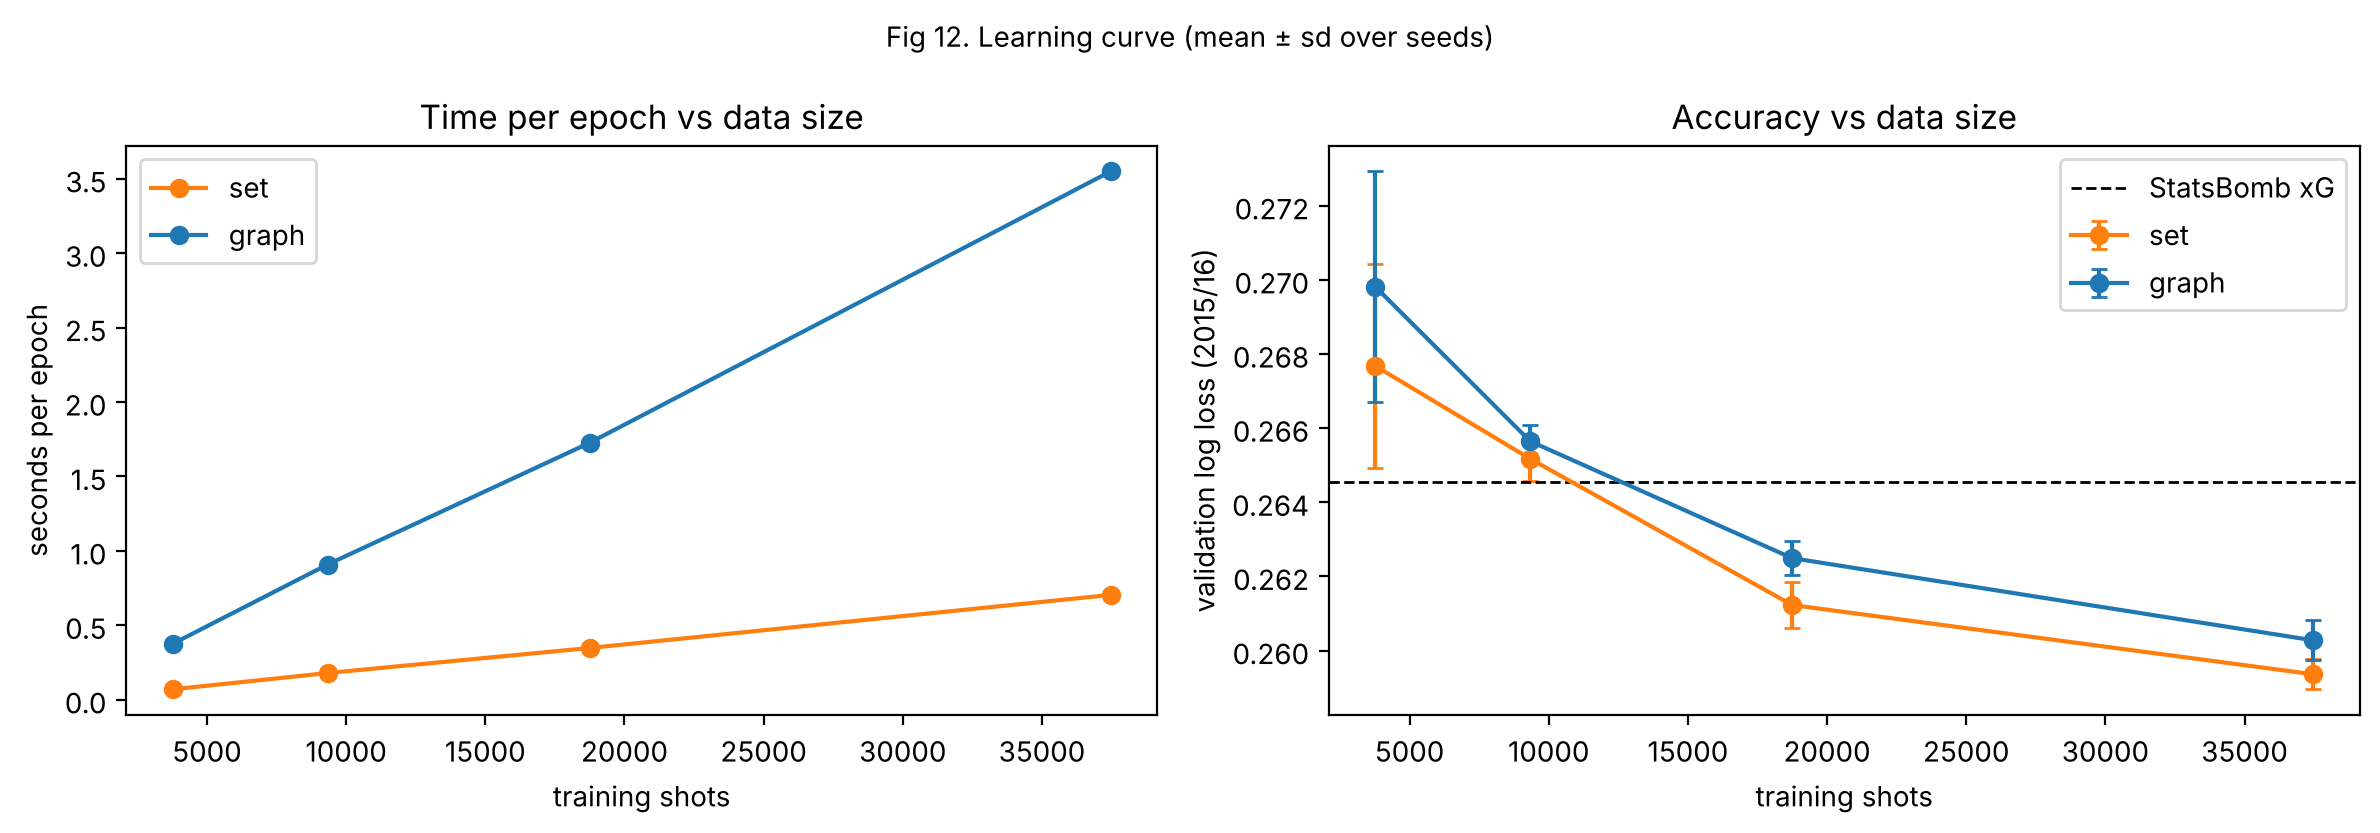

In [23]:
FRACS = [0.1, 0.25, 0.5]
curve = []
for m, cfg in FINAL.items():
    for f in FRACS + [1.0]:
        c = {**cfg, "frac": f}
        seeds = FINAL_SEEDS if f == 1.0 else CURVE_SEEDS
        if f < 1.0:
            run("7.1 learning curve", {f"{m} {int(f * 100)}%": c}, seeds=seeds)
        for s in seeds:
            r = next(r for r in RESULTS if r["key"] == (ckey(c), s))
            p = PREDS[(ckey(c), s)]["val"][IN15["val"]]
            curve.append({"model": m, "fraction": f, "seed": s, "n_train": r["n_train"],
                          "epoch_time_s": r["epoch_time_s"],
                          "val15_logloss": metrics(Y[IDX["val"][IN15["val"]]].numpy(), p)["logloss"]})
curve = pd.DataFrame(curve)
curve_sum = curve.groupby(["model", "fraction"]).agg(n_train=("n_train", "mean"), epoch_time_s=("epoch_time_s", "mean"),
                                                     val15_logloss=("val15_logloss", "mean"),
                                                     logloss_sd=("val15_logloss", "std")).reset_index()
display(curve_sum.round(4))
curve.to_csv(RESULTS_DIR / "scaling_learning_curve.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for m, c in [("set", "tab:orange"), ("graph", "tab:blue")]:
    d = curve_sum[curve_sum["model"] == m]
    ax[0].plot(d["n_train"], d["epoch_time_s"], "o-", color=c, label=m)
    ax[1].errorbar(d["n_train"], d["val15_logloss"], yerr=d["logloss_sd"].fillna(0), fmt="o-", color=c, capsize=3, label=m)
ax[0].set(xlabel="training shots", ylabel="seconds per epoch", title="Time per epoch vs data size"); ax[0].legend()
ax[1].axhline(SB_VAL15, color="k", ls="--", lw=1, label="StatsBomb xG")
ax[1].set(xlabel="training shots", ylabel="validation log loss (2015/16)", title="Accuracy vs data size"); ax[1].legend()
fig.suptitle("Fig 12. Learning curve (mean ± sd over seeds)", fontsize=10)
plt.tight_layout(); plt.savefig(FIGURES / "fig12_learning_curve.png", dpi=150); plt.show()

### 7.2 Synthetic volume
One training epoch over k copies of the training set. Batches are built on the fly from the stored graphs, so memory
does not grow with k: only the index list does. We also report how much memory the graphs would need if all of
them were held in memory at once. We stop at ×10: on our laptop ×100 would take about 8 minutes and ×1000 over an
hour just for timing, and the trend is already clearly linear.

  ×1   set      37,464 shots:    0.7 s per epoch


  ×1   graph    37,464 shots:    3.5 s per epoch


  ×2   set      74,928 shots:    1.3 s per epoch


  ×2   graph    74,928 shots:    6.7 s per epoch


  ×5   set     187,320 shots:    3.2 s per epoch


  ×5   graph   187,320 shots:   17.8 s per epoch


  ×10  set     374,640 shots:    6.8 s per epoch


  ×10  graph   374,640 shots:   36.3 s per epoch


,model,copies,shots,epoch_time_s,memory_if_all_in_RAM_GB
0,set,1,37464,0.662,0.044
1,graph,1,37464,3.475,0.054
2,set,2,74928,1.297,0.088
3,graph,2,74928,6.716,0.108
4,set,5,187320,3.215,0.219
5,graph,5,187320,17.781,0.270
6,set,10,374640,6.790,0.438
7,graph,10,374640,36.320,0.540


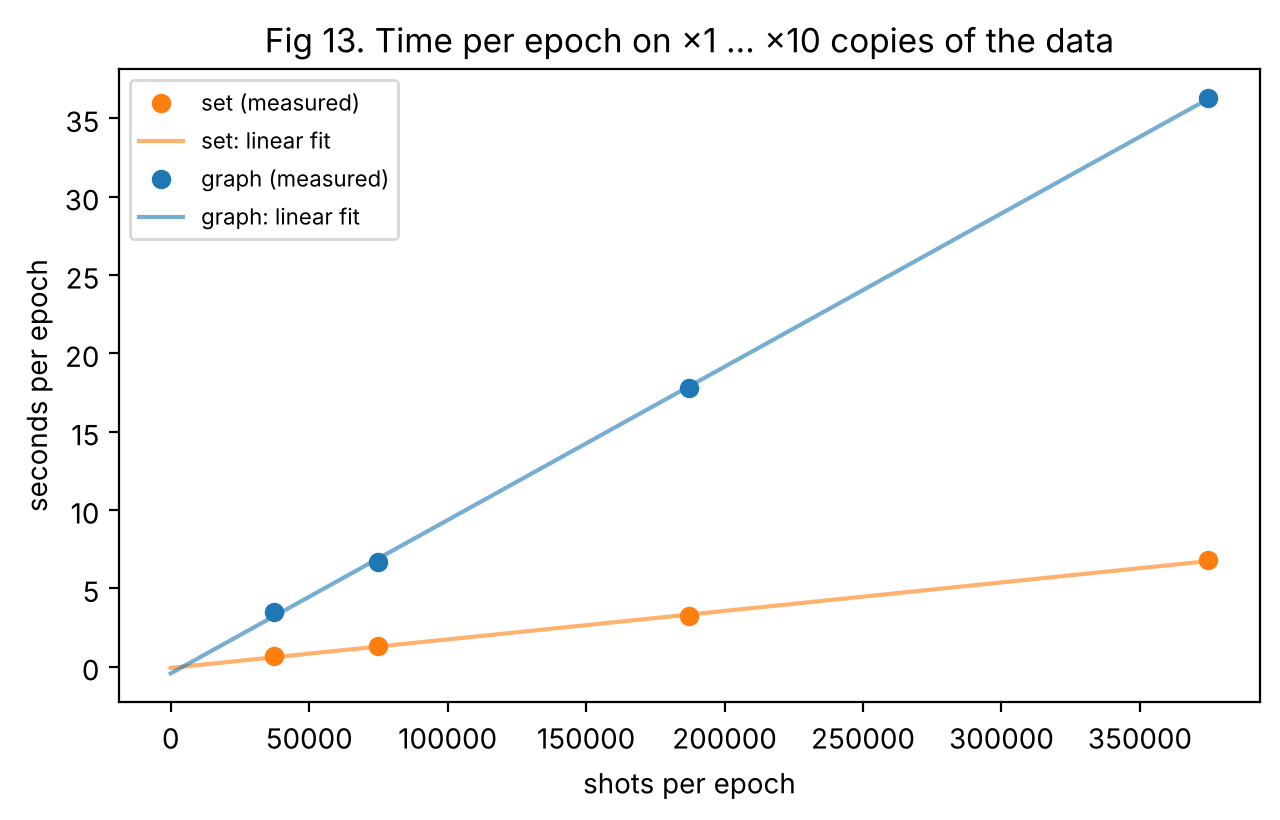

In [24]:
def time_epoch(cfg, idx, max_batches=None):
    torch.manual_seed(0)
    store = get_store(cfg["rule"], cfg["r_front"], cfg["r_back"])
    model = XGNet(X_FEATS[cfg["feats"]].shape[1], U.shape[1], rounds=0 if cfg["rule"] == "none" else 2,
                  aggr=cfg["aggr"]).to(DEVICE)
    opt, lossf = torch.optim.AdamW(model.parameters(), lr=1e-3), nn.BCEWithLogitsLoss()
    model.train(); t0, nb = time.time(), 0
    for i in range(0, len(idx), 256):
        b = store.batch(idx[i:i + 256], cfg["feats"]).to(DEVICE)
        opt.zero_grad(); lossf(model(b), b.y).backward(); opt.step(); nb += 1
        if max_batches and nb >= max_batches:
            break
    return time.time() - t0

def bytes_per_shot(cfg):
    store = get_store(cfg["rule"], cfg["r_front"], cfg["r_back"])
    nodes = NCOUNT.mean() * (X_FEATS[cfg["feats"]].shape[1] + 2) * 4     # features + x, y (float32)
    edges = store.mean_edges * (2 * 2 + 4 * 4)                            # src, dst (int16) + 4 edge features
    return nodes + edges + U.shape[1] * 4

tr = train_indices(FINAL["graph"])
synth = []
for k in S_["synth"]:
    idx = np.random.default_rng(k).permutation(np.tile(tr, k))
    for m, cfg in FINAL.items():
        t = time_epoch(cfg, idx)
        synth.append({"model": m, "copies": k, "shots": len(idx), "epoch_time_s": t,
                      "memory_if_all_in_RAM_GB": len(idx) * bytes_per_shot(cfg) / 1e9})
        print(f"  ×{k:<3} {m:<6} {len(idx):>8,} shots: {t:6.1f} s per epoch")
synth = pd.DataFrame(synth)

# straight-line fit: time = a * shots
fits = {m: np.polyfit(d["shots"], d["epoch_time_s"], 1) for m, d in synth.groupby("model")}
display(synth.round(3))
synth.to_csv(RESULTS_DIR / "scaling_synthetic.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for m, c in [("set", "tab:orange"), ("graph", "tab:blue")]:
    d = synth[synth["model"] == m]
    ax.plot(d["shots"], d["epoch_time_s"], "o", color=c, label=f"{m} (measured)")
    xs = np.linspace(0, d["shots"].max(), 50)
    ax.plot(xs, np.polyval(fits[m], xs), "-", color=c, alpha=0.6, label=f"{m}: linear fit")
ax.set(xlabel="shots per epoch", ylabel="seconds per epoch", title="Fig 13. Time per epoch on ×1 ... ×10 copies of the data")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIGURES / "fig13_synthetic_scaling.png", dpi=150); plt.show()

### 7.3 Cost per edge rule
From Experiment 5.1: time per epoch against the number of edges per shot. The message-passing cost is
O(edges × hidden²) per round, so the rule chosen decides how expensive the model is at scale.

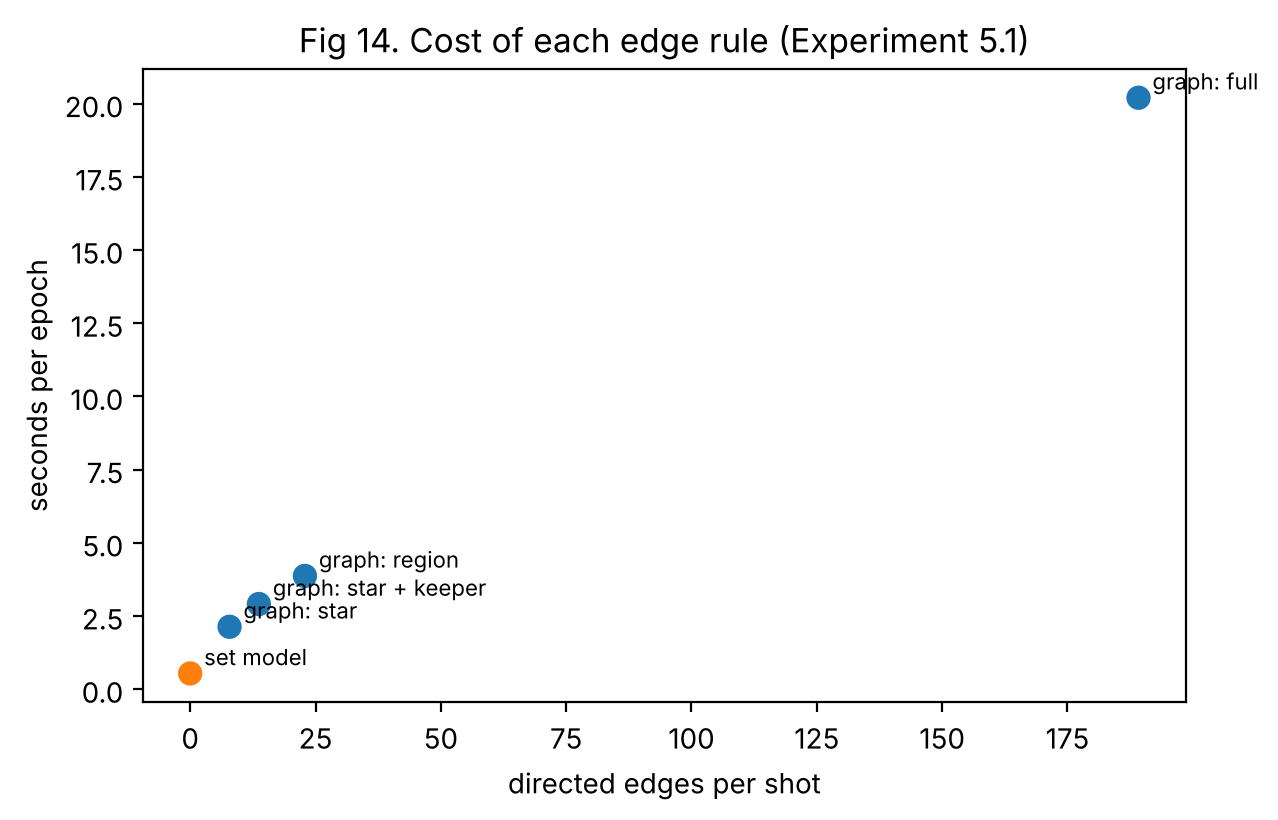

In [25]:
e1 = summary("5.1 edge rule")
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(e1["edges_per_shot"], e1["epoch_time_s"], c=e1["model"].map({"set": "tab:orange", "graph": "tab:blue"}), s=60)
for _, r in e1.iterrows():
    ax.annotate(r["name"], (r["edges_per_shot"], r["epoch_time_s"]), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set(xlabel="directed edges per shot", ylabel="seconds per epoch", title="Fig 14. Cost of each edge rule (Experiment 5.1)")
plt.tight_layout(); plt.savefig(FIGURES / "fig14_cost_per_edge_rule.png", dpi=150); plt.show()

### 7.4 Parallelism on this machine
Shots are independent graphs, so the work inside a batch can be spread over CPU cores (and, at scale, batches can be
spread over GPUs or machines with the gradients averaged). Here: a fixed number of training batches with 1, 2, 4, ... threads.

,model,threads,seconds,speed-up
0,set,1,0.24,1.00
1,graph,1,1.21,1.00
2,set,2,0.17,1.40
3,graph,2,0.95,1.27


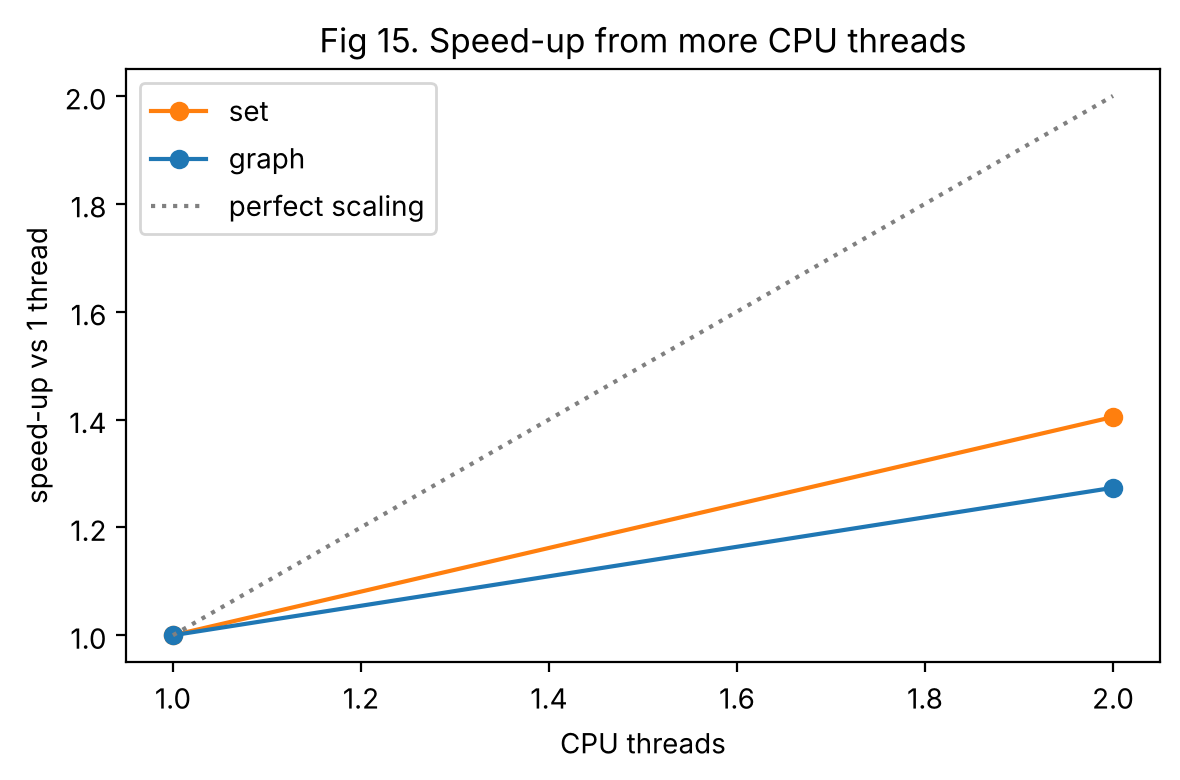

In [26]:
threads = sorted({t for t in [1, 2, 4, 8, N_THREADS] if t <= N_THREADS})
par = []
for t in threads:
    torch.set_num_threads(t)
    for m, cfg in FINAL.items():
        sec = time_epoch(cfg, tr, max_batches=S_["threads_batches"])
        par.append({"model": m, "threads": t, "seconds": sec})
torch.set_num_threads(N_THREADS)
par = pd.DataFrame(par)
par["speed-up"] = par.groupby("model")["seconds"].transform(lambda s: s.iloc[0] / s)
display(par.round(2))
par.to_csv(RESULTS_DIR / "scaling_threads.csv", index=False)
if DEVICE.type == "cuda":
    print("GPU available: the timings above were run on", torch.cuda.get_device_name(0))

fig, ax = plt.subplots(figsize=(6, 4))
for m, c in [("set", "tab:orange"), ("graph", "tab:blue")]:
    d = par[par["model"] == m]
    ax.plot(d["threads"], d["speed-up"], "o-", color=c, label=m)
ax.plot(threads, threads, ":", color="grey", label="perfect scaling")
ax.set(xlabel="CPU threads", ylabel="speed-up vs 1 thread", title="Fig 15. Speed-up from more CPU threads")
ax.legend(); plt.tight_layout(); plt.savefig(FIGURES / "fig15_threads.png", dpi=150); plt.show()

### 7.5 Extrapolating to 1000× the data
Using the linear fits from 7.2. The epoch count is taken from the final models' early stopping.

In [27]:
n_now = len(tr)
rows = []
for m, cfg in FINAL.items():
    epochs = np.mean([next(r for r in RESULTS if r["key"] == (ckey(cfg), s))["best_epoch"] + PATIENCE for s in FINAL_SEEDS])
    for k in [1, 10, 100, 1000]:
        sec = np.polyval(fits[m], n_now * k)
        rows.append({"model": m, "data volume": f"×{k}", "shots": n_now * k,
                     "hours per epoch (1 laptop)": sec / 3600,
                     "hours to train (1 laptop)": sec * epochs / 3600,
                     "memory if all in RAM (GB)": n_now * k * bytes_per_shot(cfg) / 1e9})
extrap = pd.DataFrame(rows)
display(extrap.round(3))
extrap.to_csv(RESULTS_DIR / "scaling_extrapolation.csv", index=False)

,model,data volume,shots,hours per epoch (1 laptop),hours to train (1 laptop),memory if all in RAM (GB)
0,set,×1,37464,0.000,0.002,0.044
1,set,×10,374640,0.002,0.026,0.438
2,set,×100,3746400,0.019,0.265,4.376
3,set,×1000,37464000,0.189,2.650,43.759
4,graph,×1,37464,0.001,0.012,0.054
5,graph,×10,374640,0.010,0.134,0.540
6,graph,×100,3746400,0.102,1.357,5.403
7,graph,×1000,37464000,1.019,13.581,54.028


The time to train grows linearly with the number of shots, so ×1000 data costs about ×1000 time on one machine.
Memory is not the limit as long as batches are streamed from disk rather than held in RAM.
Because shots are independent, the work divides across workers (data parallelism), so the wall-clock time can be
brought down by adding GPUs or machines.

## 8. Conclusions

In [28]:
s15 = final.loc["test15 (headline)"]
print("Final test (held-out 2015/16 matches):")
print(s15[["logloss", "brier", "auc"]].round(4))
print()
print(boot_df[["log loss difference", "95% CI low", "95% CI high", "verdict"]].round(4))
print("\nChosen configurations:")
print(chosen)

Final test (held-out 2015/16 matches):
              logloss   brier     auc
model                                
set            0.2380  0.0670  0.8214
graph          0.2379  0.0670  0.8211
StatsBomb xG   0.2389  0.0665  0.8193

                      log loss difference  95% CI low  95% CI high  \
comparison                                                           
graph − set                       -0.0001     -0.0011       0.0010   
graph − StatsBomb xG              -0.0010     -0.0051       0.0029   
set − StatsBomb xG                -0.0009     -0.0052       0.0030   

                                  verdict  
comparison                                 
graph − set           no clear difference  
graph − StatsBomb xG  no clear difference  
set − StatsBomb xG    no clear difference  

Chosen configurations:
              rule r_front r_back aggr       feats train
model                                                   
set           none       –      –  max  engineered   all
grap

*Written from our `full` run. Re-running can move the last decimal places; the printed numbers above are the ones to quote.*

**Main result (Section 6).** On the held-out 2015/16 test matches the set and graph models perform the same:
log loss 0.2380 (set) vs 0.2379 (graph), AUC 0.821 for both. The bootstrap interval for the difference,
[−0.0011, +0.0010], is centred on 0. The seed-to-seed spread (sd ≈ 0.0002) is far smaller than the effects in the
experiments, so this is a genuine tie, not noise. Connecting players into a graph did not add predictive information
beyond what the set model gets from each player's position relative to the shooter and goal.

**Both models match StatsBomb's xG** on these matches (0.2389, intervals include 0), despite being trained on about
37,000 shots. StatsBomb is a reference ceiling, and on this test set it is not clearly better or worse.

**What the experiments showed (validation, Section 5).**
* *Edge rule:* sparse, football-informed connections (`star_keeper`, 14 edges per shot) were best among the graphs;
  connecting everyone (`full`, 189 edges) was no better and about 40× slower per epoch than the set model.
* *Region size:* the default 7 / 4 yd region was best; a larger region added edges and lost accuracy.
* *Aggregation:* `max` was best for **both** models. With `max`, the set model caught up with the graph model, which
  suggests most of the information is in the single most important player (e.g. the nearest blocker or the keeper).
* *Engineered features* gave the largest improvement of any experiment, about 0.006 in log loss for both models.
  The graph model did not learn this geometry from the edges by itself.
* *Training data:* all seasons was best. Training on 2015/16 only was worse than the same number of shots drawn
  from all seasons, so the single-club seasons help through volume and did not damage predictions on normal matches.
  The focus clubs scored far more goals than every model expected (Fig 9, StatsBomb included): exceptional teams
  out-perform xG, which is a property of the teams, not something the training data fixes.

**Scaling (Section 7).** Time per epoch grows linearly with data (Fig 12, Fig 13). The graph model costs about 5× the set
model per shot, set by its edges per shot. At 1000× the data, training the graph model would take about 14 hours on one
laptop and its graphs would need about 54 GB if held in memory, so at that scale batches must be streamed from disk and
spread over several GPUs or machines. Shots are independent graphs, which makes this split straightforward.

**Limitations.** Tuning was greedy and used one seed per configuration; a single open-data source; freeze frames
show only the visible players; no tracking data (player speeds or body orientation).